<a href="https://colab.research.google.com/github/amarnathsingh72/U-net-vs-Attention-U-net/blob/mini/Beyond_Dice_Retinal_Vessel_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Beyond Dice: Junction-Level Evaluation of U-Net vs Attention U-Net

**Retinal Vessel Segmentation using DRIVE Dataset**

| Item | Detail |
|---|---|
| Framework | TensorFlow + Keras |
| Dataset | DRIVE (20 images) |
| Models | U-Net, Attention U-Net |
| Split | 14 train / 3 val / 3 test |
| Evaluation | Pixel-level + Junction-level |
| Seed | 42 |

> **Workflow:** Train U-Net → Save → Clear GPU → Train Attention U-Net → Save → Evaluate both → Junction analysis → Compare

## Cell 1 — Mount Google Drive

In [16]:
from google.colab import drive
drive.flush_and_unmount()

In [17]:
import os
import shutil
from google.colab import drive

# Clean up the mountpoint if it exists and contains stray files
mount_path = '/content/drive'
if os.path.exists(mount_path):
    try:
        shutil.rmtree(mount_path)
    except Exception:
        # If busy or cannot be fully deleted, we proceed with force_remount
        pass

# Perform a clean mount
drive.mount(mount_path, force_remount=True)

Mounted at /content/drive


## Cell 2 — Install Dependencies
TensorFlow, OpenCV, NumPy, Matplotlib, scikit-learn, and scikit-image are pre-installed on Colab.
We only need to install `patchify`.

In [18]:
import sys
import numpy as np
import tensorflow as tf

print("Python version:    ", sys.version.split()[0])
print("NumPy version:     ", np.__version__)
print("TensorFlow version:", tf.__version__)
print("✓ Environment verified. No conflicting external installs needed.")

Python version:     3.13.16
NumPy version:      2.4.6
TensorFlow version: 2.21.0
✓ Environment verified. No conflicting external installs needed.


## Cell 3 — GPU Verification & AMP Setup
Verify GPU is available and enable mixed precision (AMP) for faster training.

In [20]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.mixed_precision import set_global_policy

# ── Reproducibility ───────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# ── GPU Check ─────────────────────────────────────────────
print(f"TensorFlow: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs available: {gpus}")

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPU device: {tf.test.gpu_device_name()}")
else:
    print("⚠️  No GPU detected! Go to Runtime > Change runtime type > GPU")

# ── AMP (Mixed Precision) ────────────────────────────────
set_global_policy('mixed_float16')
print(f"Compute dtype: {tf.keras.mixed_precision.global_policy().compute_dtype}")
print(f"Variable dtype: {tf.keras.mixed_precision.global_policy().variable_dtype}")

TensorFlow: 2.21.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


RuntimeError: Physical devices cannot be modified after being initialized

## Cell 4 — Dataset Paths & Validation
Validate that all 20 images and masks are present, paired, non-corrupt, and binary.

In [ ]:
import os
print("Folders currently in your Google Drive:")
print(os.listdir('/content/drive/MyDrive'))

In [ ]:
import os
for root, dirs, files in os.walk('/content/drive/MyDrive/MINI_PROJECT'):
    print("Folder:", root)
    if dirs:
        print("  Subfolders:", dirs)
    if files:
        print("  Sample files:", files[:3])

In [ ]:
import os

print("--- Searching Google Drive for any folder named 'training' or 'DRIVE' ---")
found = False
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    # Check if this folder has retinal images or is named DRIVE
    if 'DRIVE' in [d.upper() for d in dirs] or 'training' in dirs or '1st_manual' in dirs:
        print("FOUND DATASET AT:", root)
        print("  Subfolders here:", dirs)
        found = True

if not found:
    print("Not found yet. If you just uploaded it in the browser, Colab might need to refresh Drive.")
    print("Run this to refresh: drive.flush_and_unmount() then re-run Cell 1.")

In [ ]:
import os

# Search your Google Drive for the DRIVE folder
found = []
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'DRIVE' in dirs:
        found.append(os.path.join(root, 'DRIVE'))

print("Found DRIVE folder at:")
for p in found:
    print(p)

In [ ]:
from PIL import Image

# ── Paths ─────────────────────────────────────────────────
DATA_PATH = '/content/drive/MyDrive/MINI_PROJECT/datsets/archive/DRIVE'
TRAIN_IMG_DIR  = os.path.join(DATA_PATH, 'training', 'images')
TRAIN_MASK_DIR = os.path.join(DATA_PATH, 'training', '1st_manual')
TEST_IMG_DIR   = os.path.join(DATA_PATH, 'test', 'images')

OUTPUT_BASE = '/content/drive/MyDrive/MINI_PROJECT/outputs'
os.makedirs(OUTPUT_BASE, exist_ok=True)

# ── Validate directories ─────────────────────────────────
for d in [TRAIN_IMG_DIR, TRAIN_MASK_DIR, TEST_IMG_DIR]:
    assert os.path.isdir(d), f"Missing: {d}"
    print(f"✓ {os.path.relpath(d, DATA_PATH)}: {len(os.listdir(d))} files")

# ── List and pair files ───────────────────────────────────
valid_exts = ('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.gif')
train_img_files = sorted([f for f in os.listdir(TRAIN_IMG_DIR) if f.lower().endswith(valid_exts)])
train_msk_files = sorted([f for f in os.listdir(TRAIN_MASK_DIR) if f.lower().endswith(valid_exts)])

assert len(train_img_files) == 20, f"Expected 20 images, got {len(train_img_files)}"
assert len(train_msk_files) == 20, f"Expected 20 masks, got {len(train_msk_files)}"

# ── Validate each pair ───────────────────────────────────
for img_f, msk_f in zip(train_img_files, train_msk_files):
    img = Image.open(os.path.join(TRAIN_IMG_DIR, img_f))
    msk = Image.open(os.path.join(TRAIN_MASK_DIR, msk_f)).convert('L')
    assert img.size == msk.size, f"Size mismatch: {img_f} vs {msk_f}"
    msk_arr = np.array(msk)
    assert set(np.unique(msk_arr)).issubset({0, 255}), f"Non-binary: {msk_f}"
    img.load()  # verify not corrupt

ratios = []
for msk_f in train_msk_files:
    m = np.array(Image.open(os.path.join(TRAIN_MASK_DIR, msk_f)).convert('L'))
    ratios.append(np.mean(m == 255))
print(f"\n✓ All 20 pairs validated!")
print(f"  Image size: {Image.open(os.path.join(TRAIN_IMG_DIR, train_img_files[0])).size}")
print(f"  Vessel ratio: {np.min(ratios):.3f} - {np.max(ratios):.3f} (mean {np.mean(ratios):.3f})")

## Cell 5 — Reproducible Train / Val / Test Split (14 / 3 / 3)
Split the 20 image indices into 14 train, 3 validation, 3 test using seed=42.

In [ ]:
from sklearn.model_selection import train_test_split

indices = list(range(20))

# Step 1: hold out 3 for test
train_val_idx, test_idx = train_test_split(indices, test_size=3, random_state=SEED)

# Step 2: hold out 3 for validation from remaining 17
train_idx, val_idx = train_test_split(train_val_idx, test_size=3, random_state=SEED)

print(f"Train indices ({len(train_idx)}): {sorted(train_idx)}")
print(f"Val indices   ({len(val_idx)}):  {sorted(val_idx)}")
print(f"Test indices  ({len(test_idx)}):  {sorted(test_idx)}")

## Cell 6 — Preprocessing Pipeline
- Green channel extraction
- CLAHE enhancement
- Resize to 512×512
- Normalize images to [0, 1]
- Masks: NEAREST interpolation, binarize to 0/1

In [ ]:
import cv2

IMG_SIZE = 512

def clahe_equalized(img):
    """Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)."""
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(img)

def preprocess_image(img_path):
    """Load image → green channel → CLAHE → resize 512×512 → normalize [0,1]."""
    img = np.array(Image.open(img_path))
    if len(img.shape) == 3:
        img = img[:, :, 1]  # green channel
    img = clahe_equalized(img)
    img = np.array(Image.fromarray(img).resize((IMG_SIZE, IMG_SIZE)))
    img = img.astype('float32') / 255.0
    return img[..., np.newaxis]  # (512, 512, 1)

def preprocess_mask(msk_path):
    """Load mask → grayscale → resize NEAREST → binarize to 0/1."""
    msk = Image.open(msk_path).convert('L')
    msk = msk.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
    msk = np.array(msk).astype('float32') / 255.0
    msk = (msk > 0.5).astype('float32')  # binarize
    return msk[..., np.newaxis]  # (512, 512, 1)

# ── Load all data ─────────────────────────────────────────
all_images = []
all_masks = []

for img_f, msk_f in zip(train_img_files, train_msk_files):
    all_images.append(preprocess_image(os.path.join(TRAIN_IMG_DIR, img_f)))
    all_masks.append(preprocess_mask(os.path.join(TRAIN_MASK_DIR, msk_f)))

all_images = np.array(all_images)
all_masks = np.array(all_masks)

print(f"All images shape: {all_images.shape}")
print(f"All masks shape:  {all_masks.shape}")
print(f"Image range: [{all_images.min():.3f}, {all_images.max():.3f}]")
print(f"Mask unique values: {np.unique(all_masks)}")

# ── Apply split ───────────────────────────────────────────
x_train, y_train = all_images[train_idx], all_masks[train_idx]
x_val,   y_val   = all_images[val_idx],   all_masks[val_idx]
x_test,  y_test  = all_images[test_idx],  all_masks[test_idx]

print(f"\nTrain: {x_train.shape[0]} | Val: {x_val.shape[0]} | Test: {x_test.shape[0]}")

## Cell 7 — Data Augmentation (Synchronized Image + Mask)
Random flips and 90° rotations. The **same** transform is applied to both image and mask.

In [ ]:
def augment(image, mask):
    """Synchronized augmentation: same random transform for image and mask."""
    # Random horizontal flip
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask  = tf.image.flip_left_right(mask)

    # Random vertical flip
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask  = tf.image.flip_up_down(mask)

    # Random 90-degree rotation (0, 90, 180, 270)
    k = tf.random.uniform(shape=[], maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask  = tf.image.rot90(mask, k)

    return image, mask

# Quick visual test
test_img, test_msk = augment(x_train[0], y_train[0])
print(f"Augmented image shape: {test_img.shape}, mask shape: {test_msk.shape}")

## Cell 8 — tf.data.Dataset Pipeline
Efficient data pipeline with augmentation (train only), batching, and prefetching.

In [ ]:
BATCH_SIZE = 5

def build_dataset(images, masks, batch_size, is_training=False):
    """Create a tf.data.Dataset from numpy arrays."""
    ds = tf.data.Dataset.from_tensor_slices((images, masks))

    if is_training:
        ds = ds.shuffle(buffer_size=len(images), seed=SEED,
                        reshuffle_each_iteration=True)
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = build_dataset(x_train, y_train, BATCH_SIZE, is_training=True)
val_ds   = build_dataset(x_val,   y_val,   BATCH_SIZE, is_training=False)
test_ds  = build_dataset(x_test,  y_test,  BATCH_SIZE, is_training=False)

# Verify
for batch_img, batch_msk in train_ds.take(1):
    print(f"Train batch — images: {batch_img.shape}, masks: {batch_msk.shape}")
for batch_img, batch_msk in val_ds.take(1):
    print(f"Val batch   — images: {batch_img.shape}, masks: {batch_msk.shape}")

## Cell 9 — U-Net Model
Exact architecture from the original repository. Filters: [16, 32, 64, 128, 256].

In [ ]:
from tensorflow.keras import models, layers
from tensorflow.keras import backend as K


def conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    """Two conv layers with optional BatchNorm and Dropout."""
    conv = layers.Conv2D(filters, (kernelsize, kernelsize),
                         kernel_initializer='he_normal', padding='same')(x)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation('relu')(conv)
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize),
                         kernel_initializer='he_normal', padding='same')(conv)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation('relu')(conv)
    return conv


def unetmodel(input_shape, dropout=0.2, batchnorm=True):
    """Standard U-Net with skip connections."""
    filters = [16, 32, 64, 128, 256]
    kernelsize = 3
    upsample_size = 2

    inputs = layers.Input(input_shape)

    # Encoder
    dn_1 = conv_block(inputs, kernelsize, filters[0], dropout, batchnorm)
    pool_1 = layers.MaxPooling2D(pool_size=(2, 2))(dn_1)

    dn_2 = conv_block(pool_1, kernelsize, filters[1], dropout, batchnorm)
    pool_2 = layers.MaxPooling2D(pool_size=(2, 2))(dn_2)

    dn_3 = conv_block(pool_2, kernelsize, filters[2], dropout, batchnorm)
    pool_3 = layers.MaxPooling2D(pool_size=(2, 2))(dn_3)

    dn_4 = conv_block(pool_3, kernelsize, filters[3], dropout, batchnorm)
    pool_4 = layers.MaxPooling2D(pool_size=(2, 2))(dn_4)

    dn_5 = conv_block(pool_4, kernelsize, filters[4], dropout, batchnorm)

    # Decoder
    up_5 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(dn_5)
    up_5 = layers.concatenate([up_5, dn_4], axis=3)
    up_conv_5 = conv_block(up_5, kernelsize, filters[3], dropout, batchnorm)

    up_4 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(up_conv_5)
    up_4 = layers.concatenate([up_4, dn_3], axis=3)
    up_conv_4 = conv_block(up_4, kernelsize, filters[2], dropout, batchnorm)

    up_3 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(up_conv_4)
    up_3 = layers.concatenate([up_3, dn_2], axis=3)
    up_conv_3 = conv_block(up_3, kernelsize, filters[1], dropout, batchnorm)

    up_2 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(up_conv_3)
    up_2 = layers.concatenate([up_2, dn_1], axis=3)
    up_conv_2 = conv_block(up_2, kernelsize, filters[0], dropout, batchnorm)

    conv_final = layers.Conv2D(1, kernel_size=(1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    # float32 output for numerical stability with AMP
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

# Quick test
_test_model = unetmodel((IMG_SIZE, IMG_SIZE, 1))
print(f"U-Net parameters: {_test_model.count_params():,}")
del _test_model

## Cell 10 — Attention U-Net Model
U-Net with soft attention gates at each skip connection. Uses `conv_block` from Cell 9.

In [ ]:
def gatingsignal(input, out_size, batchnorm=False):
    """Gating signal for the attention block."""
    x = layers.Conv2D(out_size, (1, 1), padding='same')(input)
    if batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x


def attention_block(x, gating, inter_shape):
    """Soft attention block."""
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)

    theta_x = layers.Conv2D(inter_shape, (2, 2), strides=(2, 2),
                            kernel_initializer='he_normal', padding='same')(x)
    shape_theta_x = K.int_shape(theta_x)

    phi_g = layers.Conv2D(inter_shape, (1, 1),
                          kernel_initializer='he_normal', padding='same')(gating)

    upsample_g = layers.Conv2DTranspose(
        inter_shape, (3, 3),
        strides=(shape_theta_x[1] // shape_g[1], shape_theta_x[2] // shape_g[2]),
        kernel_initializer='he_normal', padding='same')(phi_g)

    concat_xg = layers.add([upsample_g, theta_x])
    act_xg = layers.Activation('relu')(concat_xg)
    psi = layers.Conv2D(1, (1, 1), kernel_initializer='he_normal',
                        padding='same')(act_xg)
    sigmoid_xg = layers.Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)

    upsample_psi = layers.UpSampling2D(
        size=(shape_x[1] // shape_sigmoid[1],
              shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)

    upsample_psi = layers.Lambda(
        lambda x, repnum: K.repeat_elements(x, repnum, axis=3),
        arguments={'repnum': shape_x[3]})(upsample_psi)

    y = layers.multiply([upsample_psi, x])
    result = layers.Conv2D(shape_x[3], (1, 1),
                           kernel_initializer='he_normal', padding='same')(y)
    attenblock = layers.BatchNormalization()(result)
    return attenblock


def attentionunet(input_shape, dropout=0.2, batchnorm=True):
    """U-Net with attention gates at skip connections."""
    filters = [16, 32, 64, 128, 256]
    kernelsize = 3
    upsample_size = 2

    inputs = layers.Input(input_shape)

    # Encoder
    dn_1 = conv_block(inputs, kernelsize, filters[0], dropout, batchnorm)
    pool_1 = layers.MaxPooling2D(pool_size=(2, 2))(dn_1)

    dn_2 = conv_block(pool_1, kernelsize, filters[1], dropout, batchnorm)
    pool_2 = layers.MaxPooling2D(pool_size=(2, 2))(dn_2)

    dn_3 = conv_block(pool_2, kernelsize, filters[2], dropout, batchnorm)
    pool_3 = layers.MaxPooling2D(pool_size=(2, 2))(dn_3)

    dn_4 = conv_block(pool_3, kernelsize, filters[3], dropout, batchnorm)
    pool_4 = layers.MaxPooling2D(pool_size=(2, 2))(dn_4)

    dn_5 = conv_block(pool_4, kernelsize, filters[4], dropout, batchnorm)

    # Decoder with attention
    gating_5 = gatingsignal(dn_5, filters[3], batchnorm)
    att_5 = attention_block(dn_4, gating_5, filters[3])
    up_5 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(dn_5)
    up_5 = layers.concatenate([up_5, att_5], axis=3)
    up_conv_5 = conv_block(up_5, kernelsize, filters[3], dropout, batchnorm)

    gating_4 = gatingsignal(up_conv_5, filters[2], batchnorm)
    att_4 = attention_block(dn_3, gating_4, filters[2])
    up_4 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(up_conv_5)
    up_4 = layers.concatenate([up_4, att_4], axis=3)
    up_conv_4 = conv_block(up_4, kernelsize, filters[2], dropout, batchnorm)

    gating_3 = gatingsignal(up_conv_4, filters[1], batchnorm)
    att_3 = attention_block(dn_2, gating_3, filters[1])
    up_3 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(up_conv_4)
    up_3 = layers.concatenate([up_3, att_3], axis=3)
    up_conv_3 = conv_block(up_3, kernelsize, filters[1], dropout, batchnorm)

    gating_2 = gatingsignal(up_conv_3, filters[0], batchnorm)
    att_2 = attention_block(dn_1, gating_2, filters[0])
    up_2 = layers.UpSampling2D(size=(upsample_size, upsample_size),
                               data_format='channels_last')(up_conv_3)
    up_2 = layers.concatenate([up_2, att_2], axis=3)
    up_conv_2 = conv_block(up_2, kernelsize, filters[0], dropout, batchnorm)

    conv_final = layers.Conv2D(1, kernel_size=(1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

# Quick test
_test_model = attentionunet((IMG_SIZE, IMG_SIZE, 1))
print(f"Attention U-Net parameters: {_test_model.count_params():,}")
del _test_model

## Cell 11 — BCE + Dice Loss Function
Combined Binary Cross-Entropy + Dice Loss.
- BCE: pixel-wise classification accuracy
- Dice: region-level overlap, handles class imbalance

In [ ]:
def dice_coef(y_true, y_pred):
    """Dice coefficient (F1 for segmentation)."""
    y_true_f = K.flatten(K.cast(y_true, 'float32'))
    y_pred_f = K.flatten(K.cast(y_pred, 'float32'))
    intersection = K.sum(y_true_f * y_pred_f)
    return (2.0 * intersection + 1.0) / (K.sum(y_true_f) + K.sum(y_pred_f) + 1.0)


def IoU_coef(y_true, y_pred):
    """Intersection over Union (Jaccard index)."""
    y_true_f = K.flatten(K.cast(y_true, 'float32'))
    y_pred_f = K.flatten(K.cast(y_pred, 'float32'))
    intersection = K.sum(y_true_f * y_pred_f)
    return (intersection + 1.0) / (K.sum(y_true_f) + K.sum(y_pred_f) - intersection + 1.0)


def bce_dice_loss(y_true, y_pred):
    """Combined BCE + Dice loss."""
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    bce = K.mean(bce)
    dice_loss = 1.0 - dice_coef(y_true, y_pred)
    return bce + dice_loss

print("Loss and metrics defined: bce_dice_loss, dice_coef, IoU_coef")

## Cell 12 — Callbacks
- **EarlyStopping**: patience=20, restore best weights
- **ReduceLROnPlateau**: patience=10, factor=0.5
- **ModelCheckpoint**: save best model only
- **CSVLogger**: log all metrics per epoch

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
)

def get_callbacks(model_name):
    """Create callbacks for a given model. Saves to Google Drive."""
    save_dir = os.path.join(OUTPUT_BASE, model_name)
    ckpt_dir = os.path.join(save_dir, 'checkpoints')
    log_dir  = os.path.join(save_dir, 'logs')
    os.makedirs(ckpt_dir, exist_ok=True)
    os.makedirs(log_dir, exist_ok=True)

    return [
        EarlyStopping(
            monitor='val_loss', patience=50,          # Gives 50 epochs to improve
            restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(
            monitor='val_loss', patience=15,          # Lowers LR after 15 epochs of plateau
            factor=0.5, min_lr=1e-6, verbose=1),
        ModelCheckpoint(
            filepath=os.path.join(ckpt_dir, f'best_{model_name}.h5'),
            monitor='val_loss', save_best_only=True, verbose=1),
        CSVLogger(
            os.path.join(log_dir, f'training_log_{model_name}.csv'),
            append=False),
    ]

print("Callback factory ready (EarlyStopping=50, ReduceLR=15).")

## Cell 13 — Training Configuration
All hyperparameters in one place. Models are trained **separately**.

In [ ]:
# ── Hyperparameters ───────────────────────────────────────
EPOCHS = 300
LEARNING_RATE = 1e-3
input_shape = (IMG_SIZE, IMG_SIZE, 1)

def build_and_compile(model_name):
    """Build and compile the specified model."""
    if model_name == 'unet':
        model = unetmodel(input_shape)
    elif model_name == 'attention_unet':
        model = attentionunet(input_shape)
    else:
        raise ValueError(f"Unknown model: {model_name}")

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss=bce_dice_loss,
        metrics=['accuracy', dice_coef, IoU_coef],
    )
    return model

from tensorflow.keras.optimizers import Adam
print(f"Config: epochs={EPOCHS}, batch_size={BATCH_SIZE}, lr={LEARNING_RATE}")
print(f"Input shape: {input_shape}")

## Cell 14 — Train U-Net
Full training run with all callbacks. This may take 30-60 minutes on Colab GPU.

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
)

# ── Updated Callbacks: Monitor val_dice_coef (MAX) instead of val_loss ──
unet_callbacks_v2 = [
    EarlyStopping(
        monitor='val_dice_coef', mode='max', patience=40,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_dice_coef', mode='max', patience=15,
        factor=0.5, min_lr=1e-6, verbose=1
    ),
    ModelCheckpoint(
        filepath=os.path.join(OUTPUT_BASE, 'unet', 'checkpoints', 'best_unet.h5'),
        monitor='val_dice_coef', mode='max', save_best_only=True, verbose=1
    ),
    CSVLogger(
        os.path.join(OUTPUT_BASE, 'unet', 'logs', 'training_log_unet_v2.csv'),
        append=False
    ),
]

print("Training U-Net targeting maximum Vessel Dice...")

unet_model = build_and_compile('unet')

unet_history = unet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=150,
    callbacks=unet_callbacks_v2,
    verbose=1,
)

print("\n✓ U-Net training complete with best Dice weights restored!")

## Cell 15 — Save U-Net Results & Plots

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

def save_training_plots(history, model_name):
    """Save loss, accuracy, Dice, and IoU plots to Google Drive."""
    plot_dir = os.path.join(OUTPUT_BASE, model_name, 'plots')
    os.makedirs(plot_dir, exist_ok=True)

    h = history.history
    epochs_range = range(1, len(h['loss']) + 1)

    # Auto-detect whether Keras used 'IoU_coef' or 'io_u_coef'
    iou_key = 'io_u_coef' if 'io_u_coef' in h else 'IoU_coef'
    val_iou_key = f'val_{iou_key}'

    plots = [
        ('loss', 'val_loss', 'Loss', 'BCE + Dice Loss'),
        ('accuracy', 'val_accuracy', 'Accuracy', 'Accuracy'),
        ('dice_coef', 'val_dice_coef', 'Dice Coefficient', 'Dice'),
        (iou_key, val_iou_key, 'IoU', 'IoU'),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'{model_name.upper()} Training Curves', fontsize=16)

    for ax, (train_key, val_key, ylabel, title) in zip(axes.flat, plots):
        ax.plot(epochs_range, h[train_key], 'r-', label='Train')
        ax.plot(epochs_range, h[val_key], 'b-', label='Val')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    save_path = os.path.join(plot_dir, f'training_curves_{model_name}.png')
    plt.savefig(save_path, dpi=150)
    plt.show()

    # Print best epoch stats
    best_epoch = np.argmin(h['val_loss']) + 1
    print(f"\nBest epoch: {best_epoch}")
    print(f"  val_loss:  {h['val_loss'][best_epoch-1]:.6f}")
    print(f"  val_dice:  {h['val_dice_coef'][best_epoch-1]:.6f}")
    print(f"  val_IoU:   {h[val_iou_key][best_epoch-1]:.6f}")
    print(f"Plots saved to: {save_path}")

save_training_plots(unet_history, 'unet')

## Cell 16 — Clear GPU Memory
Free GPU memory before training Attention U-Net.

In [ ]:
import gc

# Save history for later comparison
unet_hist_dict = unet_history.history.copy()

# Delete model and clear session
del unet_model
del unet_history
K.clear_session()
gc.collect()

# Rebuild datasets (session was cleared)
tf.random.set_seed(SEED)
train_ds = build_dataset(x_train, y_train, BATCH_SIZE, is_training=True)
val_ds   = build_dataset(x_val,   y_val,   BATCH_SIZE, is_training=False)
test_ds  = build_dataset(x_test,  y_test,  BATCH_SIZE, is_training=False)

print("GPU memory cleared. Ready for Attention U-Net training.")

## Cell 17 — Train Attention U-Net
Same configuration as U-Net. This may take 40-70 minutes on Colab GPU.

In [ ]:
print("=" * 60)
print("  TRAINING: ATTENTION U-NET")
print("=" * 60)

att_model = build_and_compile('attention_unet')
att_model.summary()

att_callbacks = get_callbacks('attention_unet')

att_history = att_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=att_callbacks,
    verbose=1,
)

# Save final model
att_final_path = os.path.join(OUTPUT_BASE, 'attention_unet', 'checkpoints', 'final_attention_unet.h5')
att_model.save(att_final_path)
print(f"\nFinal Attention U-Net saved to: {att_final_path}")

## Cell 18 — Save Attention U-Net Results & Plots

In [ ]:
save_training_plots(att_history, 'attention_unet')

# Save history for comparison
att_hist_dict = att_history.history.copy()

## Cell 19 — Pixel-Level Evaluation Metrics
Evaluate both models on the **test set** (3 images).
Metrics: Dice, IoU, Precision, Recall, Accuracy

In [5]:
import os
import cv2
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, jaccard_score, accuracy_score
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras import backend as K

# ── 1. Paths & Verification ───────────────────────────────────────────
DATA_PATH = '/content/drive/MyDrive/MINI_PROJECT/datsets/archive/DRIVE'
TRAIN_IMG_DIR  = os.path.join(DATA_PATH, 'training', 'images')
TRAIN_MASK_DIR = os.path.join(DATA_PATH, 'training', '1st_manual')
OUTPUT_BASE = '/content/drive/MyDrive/MINI_PROJECT/outputs'

unet_path = os.path.join(OUTPUT_BASE, 'unet', 'checkpoints', 'best_unet.h5')
att_path  = os.path.join(OUTPUT_BASE, 'attention_unet', 'checkpoints', 'best_attention_unet.h5')

assert os.path.exists(unet_path), f"Cannot find U-Net checkpoint: {unet_path}"
assert os.path.exists(att_path), f"Cannot find Attention U-Net checkpoint: {att_path}"

# ── 2. Re-create the Exact 14/3/3 Test Split ──────────────────────────
SEED = 42
IMG_SIZE = 512

def clahe_equalized(img):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(img)

def preprocess_image(img_path):
    img = np.array(Image.open(img_path))
    if len(img.shape) == 3:
        img = img[:, :, 1]
    img = clahe_equalized(img)
    img = np.array(Image.fromarray(img).resize((IMG_SIZE, IMG_SIZE)))
    return (img.astype('float32') / 255.0)[..., np.newaxis]

def preprocess_mask(msk_path):
    msk = Image.open(msk_path).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
    msk = (np.array(msk).astype('float32') / 255.0 > 0.5).astype('float32')
    return msk[..., np.newaxis]

valid_exts = ('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.gif')
train_img_files = sorted([f for f in os.listdir(TRAIN_IMG_DIR) if f.lower().endswith(valid_exts)])
train_msk_files = sorted([f for f in os.listdir(TRAIN_MASK_DIR) if f.lower().endswith(valid_exts)])

# Load only test images (indices 0, 15, 17 from seed 42 split)
indices = list(range(20))
train_val_idx, test_idx = train_test_split(indices, test_size=3, random_state=SEED)
print(f"Test indices (holdout): {sorted(test_idx)}")

x_test = np.array([preprocess_image(os.path.join(TRAIN_IMG_DIR, train_img_files[i])) for i in test_idx])
y_test = np.array([preprocess_mask(os.path.join(TRAIN_MASK_DIR, train_msk_files[i])) for i in test_idx])

# ── 3. Build Model Architectures ──────────────────────────────────────
def conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation('relu')(conv)
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(conv)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    return layers.Activation('relu')(conv)

def build_unet(input_shape=(512, 512, 1)):
    filters = [16, 32, 64, 128, 256]
    inputs = layers.Input(input_shape)

    dn_1 = conv_block(inputs, 3, filters[0], 0.2, True)
    pool_1 = layers.MaxPooling2D((2, 2))(dn_1)
    dn_2 = conv_block(pool_1, 3, filters[1], 0.2, True)
    pool_2 = layers.MaxPooling2D((2, 2))(dn_2)
    dn_3 = conv_block(pool_2, 3, filters[2], 0.2, True)
    pool_3 = layers.MaxPooling2D((2, 2))(dn_3)
    dn_4 = conv_block(pool_3, 3, filters[3], 0.2, True)
    pool_4 = layers.MaxPooling2D((2, 2))(dn_4)
    dn_5 = conv_block(pool_4, 3, filters[4], 0.2, True)

    up_5 = layers.UpSampling2D((2, 2))(dn_5)
    up_5 = layers.concatenate([up_5, dn_4], axis=3)
    up_conv_5 = conv_block(up_5, 3, filters[3], 0.2, True)

    up_4 = layers.UpSampling2D((2, 2))(up_conv_5)
    up_4 = layers.concatenate([up_4, dn_3], axis=3)
    up_conv_4 = conv_block(up_4, 3, filters[2], 0.2, True)

    up_3 = layers.UpSampling2D((2, 2))(up_conv_4)
    up_3 = layers.concatenate([up_3, dn_2], axis=3)
    up_conv_3 = conv_block(up_3, 3, filters[1], 0.2, True)

    up_2 = layers.UpSampling2D((2, 2))(up_conv_3)
    up_2 = layers.concatenate([up_2, dn_1], axis=3)
    up_conv_2 = conv_block(up_2, 3, filters[0], 0.2, True)

    conv_final = layers.Conv2D(1, (1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)
    return models.Model(inputs=[inputs], outputs=[outputs])

def gatingsignal(input, out_size, batchnorm=False):
    x = layers.Conv2D(out_size, (1, 1), padding='same')(input)
    if batchnorm:
        x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def attention_block(x, gating, inter_shape):
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)
    theta_x = layers.Conv2D(inter_shape, (2, 2), strides=(2, 2), kernel_initializer='he_normal', padding='same')(x)
    shape_theta_x = K.int_shape(theta_x)
    phi_g = layers.Conv2D(inter_shape, (1, 1), kernel_initializer='he_normal', padding='same')(gating)
    upsample_g = layers.Conv2DTranspose(inter_shape, (3, 3), strides=(shape_theta_x[1] // shape_g[1], shape_theta_x[2] // shape_g[2]), kernel_initializer='he_normal', padding='same')(phi_g)
    concat_xg = layers.add([upsample_g, theta_x])
    act_xg = layers.Activation('relu')(concat_xg)
    psi = layers.Conv2D(1, (1, 1), kernel_initializer='he_normal', padding='same')(act_xg)
    sigmoid_xg = layers.Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)
    upsample_psi = layers.UpSampling2D(size=(shape_x[1] // shape_sigmoid[1], shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)
    upsample_psi = layers.Lambda(lambda x, repnum: K.repeat_elements(x, repnum, axis=3), arguments={'repnum': shape_x[3]})(upsample_psi)
    y = layers.multiply([upsample_psi, x])
    result = layers.Conv2D(shape_x[3], (1, 1), kernel_initializer='he_normal', padding='same')(y)
    return layers.BatchNormalization()(result)

def build_attention_unet(input_shape=(512, 512, 1)):
    filters = [16, 32, 64, 128, 256]
    inputs = layers.Input(input_shape)

    dn_1 = conv_block(inputs, 3, filters[0], 0.2, True)
    pool_1 = layers.MaxPooling2D((2, 2))(dn_1)
    dn_2 = conv_block(pool_1, 3, filters[1], 0.2, True)
    pool_2 = layers.MaxPooling2D((2, 2))(dn_2)
    dn_3 = conv_block(pool_2, 3, filters[2], 0.2, True)
    pool_3 = layers.MaxPooling2D((2, 2))(dn_3)
    dn_4 = conv_block(pool_3, 3, filters[3], 0.2, True)
    pool_4 = layers.MaxPooling2D((2, 2))(dn_4)
    dn_5 = conv_block(pool_4, 3, filters[4], 0.2, True)

    gating_5 = gatingsignal(dn_5, filters[3], True)
    att_5 = attention_block(dn_4, gating_5, filters[3])
    up_5 = layers.UpSampling2D((2, 2))(dn_5)
    up_5 = layers.concatenate([up_5, att_5], axis=3)
    up_conv_5 = conv_block(up_5, 3, filters[3], 0.2, True)

    gating_4 = gatingsignal(up_conv_4 := up_conv_5, filters[2], True)
    att_4 = attention_block(dn_3, gating_4, filters[2])
    up_4 = layers.UpSampling2D((2, 2))(up_conv_4)
    up_4 = layers.concatenate([up_4, att_4], axis=3)
    up_conv_4 = conv_block(up_4, 3, filters[2], 0.2, True)

    gating_3 = gatingsignal(up_conv_3 := up_conv_4, filters[1], True)
    att_3 = attention_block(dn_2, gating_3, filters[1])
    up_3 = layers.UpSampling2D((2, 2))(up_conv_3)
    up_3 = layers.concatenate([up_3, att_3], axis=3)
    up_conv_3 = conv_block(up_3, 3, filters[1], 0.2, True)

    gating_2 = gatingsignal(up_conv_2 := up_conv_3, filters[0], True)
    att_2 = attention_block(dn_1, gating_2, filters[0])
    up_2 = layers.UpSampling2D((2, 2))(up_conv_2)
    up_2 = layers.concatenate([up_2, att_2], axis=3)
    up_conv_2 = conv_block(up_2, 3, filters[0], 0.2, True)

    conv_final = layers.Conv2D(1, (1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)
    return models.Model(inputs=[inputs], outputs=[outputs])

# ── 4. Load Models & Weights ──────────────────────────────────────────
print("\nLoading models and weights from Google Drive...")
unet_eval_model = build_unet()
att_eval_model  = build_attention_unet()

unet_eval_model.load_weights(unet_path)
att_eval_model.load_weights(att_path)
print("✓ Both pre-trained models loaded successfully.")

# ── 5. Evaluate on Test Set ───────────────────────────────────────────
def evaluate_model_on_test(model, x_test, y_test, model_name):
    preds = model.predict(x_test, verbose=0)
    preds_binary = (preds > 0.5).astype(np.float32)

    results = {'model': model_name}
    all_dice, all_iou, all_prec, all_rec, all_acc = [], [], [], [], []

    for i in range(len(x_test)):
        y_true = y_test[i].flatten().astype(int)
        y_pred = preds_binary[i].flatten().astype(int)

        all_acc.append(accuracy_score(y_true, y_pred))
        all_prec.append(precision_score(y_true, y_pred, zero_division=0))
        all_rec.append(recall_score(y_true, y_pred, zero_division=0))
        all_iou.append(jaccard_score(y_true, y_pred, zero_division=0))
        iou = all_iou[-1]
        all_dice.append(2 * iou / (1 + iou) if iou > 0 else 0)

    results['accuracy']  = np.mean(all_acc)
    results['precision'] = np.mean(all_prec)
    results['recall']    = np.mean(all_rec)
    results['iou']       = np.mean(all_iou)
    results['dice']      = np.mean(all_dice)

    print(f"\n{'='*40}")
    print(f"  {model_name.upper()} — Test Results")
    print(f"{'='*40}")
    for k, v in results.items():
        if k != 'model':
            print(f"  {k:12s}: {v:.6f}")

    return results, preds_binary

unet_results, unet_preds = evaluate_model_on_test(unet_eval_model, x_test, y_test, 'unet')
att_results, att_preds   = evaluate_model_on_test(att_eval_model, x_test, y_test, 'attention_unet')

Test indices (holdout): [0, 15, 17]

Loading models and weights from Google Drive...
✓ Both pre-trained models loaded successfully.

  UNET — Test Results
  accuracy    : 0.912663
  precision   : 0.505741
  recall      : 0.899940
  iou         : 0.478464
  dice        : 0.647035

  ATTENTION_UNET — Test Results
  accuracy    : 0.952914
  precision   : 0.679105
  recall      : 0.895382
  iou         : 0.628379
  dice        : 0.771564


## Cell 20 — Visual Comparison
Side-by-side: Original image, Ground Truth, U-Net prediction, Attention U-Net prediction, Overlays.

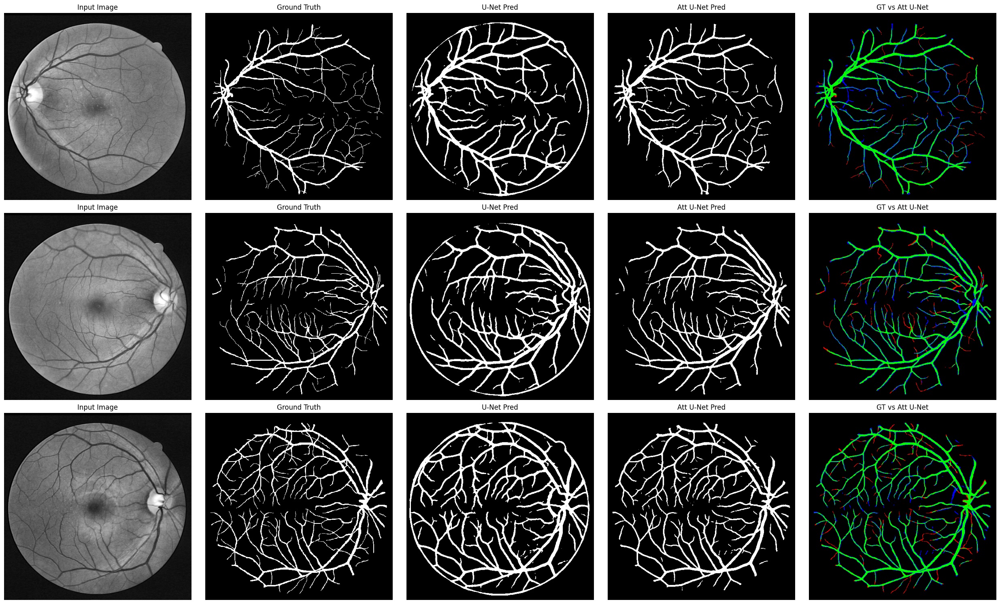

Saved to: /content/drive/MyDrive/MINI_PROJECT/outputs/visual_comparison.png


In [23]:
def plot_comparison(x_test, y_test, unet_preds, att_preds, num_samples=3):
    """Plot visual comparison for test samples."""
    fig, axes = plt.subplots(num_samples, 5, figsize=(25, 5 * num_samples))
    titles = ['Input Image', 'Ground Truth', 'U-Net Pred', 'Att U-Net Pred', 'GT vs Att U-Net']

    for i in range(num_samples):
        img   = x_test[i, :, :, 0]
        gt    = y_test[i, :, :, 0]
        u_pred = unet_preds[i, :, :, 0]
        a_pred = att_preds[i, :, :, 0]

        # Overlay: Green=TP, Red=FN, Blue=FP
        overlay = np.zeros((IMG_SIZE, IMG_SIZE, 3))
        overlay[:, :, 1] = (gt * a_pred)           # TP = green
        overlay[:, :, 0] = (gt * (1 - a_pred))     # FN = red
        overlay[:, :, 2] = ((1 - gt) * a_pred)     # FP = blue

        panels = [img, gt, u_pred, a_pred, overlay]
        cmaps  = ['gray', 'gray', 'gray', 'gray', None]

        for j, (panel, cmap) in enumerate(zip(panels, cmaps)):
            axes[i, j].imshow(panel, cmap=cmap)
            axes[i, j].set_title(titles[j], fontsize=12)
            axes[i, j].axis('off')

    plt.tight_layout()
    save_path = os.path.join(OUTPUT_BASE, 'visual_comparison.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved to: {save_path}")

plot_comparison(x_test, y_test, unet_preds, att_preds)

## Cell 21 — Junction-Level Evaluation (Phase 5)
**This is the core research contribution.**

1. Skeletonize binary predictions and ground truth
2. Detect junction pixels (3+ skeleton neighbors in 8-connectivity)
3. Compute junction-level Dice, Precision, Recall (with tolerance radius)
4. Failure analysis: missed vs spurious junctions

In [6]:
# ==============================================================================
# ── Enhanced Junction Failure Maps & Comparative Analysis ─────────────────────
# ==============================================================================
import cv2
from matplotlib.patches import Patch
from scipy.ndimage import binary_dilation

def generate_junction_failure_maps(
    x_test, y_test, unet_preds, att_preds,
    unet_details, att_details, tolerance=3, output_dir=OUTPUT_BASE
):
    """
    Generates a 6-panel failure map for each test image:
      1. Original Retinal Image (Green channel, gray)
      2. Ground Truth Mask (binary, gray)
      3. GT Skeleton with ALL true junctions as GREEN dots
      4. U-Net Failure Map (White skeleton, Green=TP, Red=FN, Blue=FP)
      5. Attention U-Net Failure Map (White skeleton, Green=TP, Red=FN, Blue=FP)
      6. 150x150 Zoomed crop centered on highest density of Attention U-Net missed junctions (FN)
    """
    struct = np.ones((2 * tolerance + 1, 2 * tolerance + 1), dtype=np.uint8)

    for i in range(len(y_test)):
        orig_img = x_test[i, :, :, 0]
        gt_mask  = y_test[i, :, :, 0].astype(np.uint8)
        u_mask   = unet_preds[i, :, :, 0].astype(np.uint8)
        a_mask   = att_preds[i, :, :, 0].astype(np.uint8)

        # Skeletons
        skel_gt = extract_skeleton(gt_mask)
        skel_u  = extract_skeleton(u_mask)
        skel_a  = extract_skeleton(a_mask)

        # Junction points (binary masks)
        j_gt = detect_junctions(skel_gt)
        j_u  = detect_junctions(skel_u)
        j_a  = detect_junctions(skel_a)

        # Dilations for tolerance-3 matching
        gt_dil = binary_dilation(j_gt, structure=struct).astype(np.uint8)
        u_dil  = binary_dilation(j_u, structure=struct).astype(np.uint8)
        a_dil  = binary_dilation(j_a, structure=struct).astype(np.uint8)

        # Panel 3: Base GT Skeleton with Green Junctions
        # Dark gray background (51, 51, 51) and white skeleton (255, 255, 255)
        p3_canvas = np.full((512, 512, 3), 51, dtype=np.uint8)
        p3_canvas[skel_gt > 0] = [255, 255, 255]
        gt_pts = np.argwhere(j_gt > 0)
        for pt in gt_pts:
            cv2.circle(p3_canvas, (pt[1], pt[0]), 4, (0, 255, 0), -1)  # Green circle radius 4px

        def build_failure_canvas(skel, j_pred, pred_dil):
            """Builds white skeleton on dark gray background with TP (Green), FN (Red), FP (Blue) dots."""
            canvas = np.full((512, 512, 3), 51, dtype=np.uint8)
            canvas[skel > 0] = [255, 255, 255]

            # TP: predicted junctions falling within dilated GT (radius tolerance)
            tp_pts = np.argwhere((j_pred > 0) & (gt_dil > 0))
            # FP: predicted junctions that do NOT fall within dilated GT
            fp_pts = np.argwhere((j_pred > 0) & (gt_dil == 0))
            # FN: GT junctions that were NOT detected by prediction
            fn_pts = np.argwhere((j_gt > 0) & (pred_dil == 0))

            # Draw circles using radius 4px
            for pt in tp_pts:
                cv2.circle(canvas, (pt[1], pt[0]), 4, (0, 255, 0), -1)    # Green (TP)
            for pt in fn_pts:
                cv2.circle(canvas, (pt[1], pt[0]), 4, (255, 0, 0), -1)    # Red (FN)
            for pt in fp_pts:
                cv2.circle(canvas, (pt[1], pt[0]), 4, (0, 0, 255), -1)    # Blue (FP)

            return canvas, tp_pts, fn_pts, fp_pts

        p4_canvas, u_tp, u_fn, u_fp = build_failure_canvas(skel_u, j_u, u_dil)
        p5_canvas, a_tp, a_fn, a_fp = build_failure_canvas(skel_a, j_a, a_dil)

        # Panel 6: Crop 150x150 centered on highest density of Attention U-Net FN (Red dots)
        if len(a_fn) > 0:
            fn_density = cv2.GaussianBlur(
                ((j_gt > 0) & (a_dil == 0)).astype(np.float32), (31, 31), 5.0
            )
            cy, cx = np.unravel_index(np.argmax(fn_density), fn_density.shape)
        else:
            cy, cx = 256, 256

        half_crop = 75
        y1 = max(0, min(512 - 150, cy - half_crop))
        y2 = y1 + 150
        x1 = max(0, min(512 - 150, cx - half_crop))
        x2 = x1 + 150

        crop_patch = p5_canvas[y1:y2, x1:x2].copy()
        cv2.rectangle(crop_patch, (0, 0), (149, 149), (255, 255, 255), 2)  # White border on crop

        # Show crop bounding box (Yellow) on Panel 5
        p5_display = p5_canvas.copy()
        cv2.rectangle(p5_display, (x1, y1), (x2, y2), (255, 255, 0), 2)

        # Build 6-panel Figure
        fig, axes = plt.subplots(2, 3, figsize=(24, 16))

        # Panel 1: Original retinal green channel
        axes[0, 0].imshow(orig_img, cmap='gray')
        axes[0, 0].set_title(f'Panel 1: Test Image #{i+1} — Green Channel', fontsize=14, fontweight='bold')
        axes[0, 0].axis('off')

        # Panel 2: GT vessel mask
        axes[0, 1].imshow(gt_mask, cmap='gray')
        axes[0, 1].set_title('Panel 2: Ground Truth Vessel Mask (DRIVE)', fontsize=14, fontweight='bold')
        axes[0, 1].axis('off')

        # Panel 3: GT skeleton with true junctions
        axes[0, 2].imshow(p3_canvas.astype(np.float32) / 255.0)
        axes[0, 2].set_title(f'Panel 3: GT Skeleton & True Junctions (n={len(gt_pts)})', fontsize=14, fontweight='bold')
        axes[0, 2].axis('off')

        # Panel 4: U-Net failure map
        u_dice = unet_details[i]['dice']
        axes[1, 0].imshow(p4_canvas.astype(np.float32) / 255.0)
        axes[1, 0].set_title(
            f'Panel 4: U-Net Failure Map\n(TP={len(u_tp)}, FN={len(u_fn)}, FP={len(u_fp)}) | J-Dice: {u_dice:.3f}',
            fontsize=14, fontweight='bold'
        )
        axes[1, 0].axis('off')

        # Panel 5: Attention U-Net failure map
        a_dice = att_details[i]['dice']
        axes[1, 1].imshow(p5_display.astype(np.float32) / 255.0)
        axes[1, 1].set_title(
            f'Panel 5: Attention U-Net Failure Map\n(TP={len(a_tp)}, FN={len(a_fn)}, FP={len(a_fp)}) | J-Dice: {a_dice:.3f}',
            fontsize=14, fontweight='bold'
        )
        axes[1, 1].axis('off')

        # Panel 6: Zoomed crop of worst failure
        axes[1, 2].imshow(crop_patch.astype(np.float32) / 255.0)
        axes[1, 2].set_title(
            'Panel 6: Zoomed Worst Failure Region (150x150)\nCentered on Attention U-Net FN Density',
            fontsize=14, fontweight='bold'
        )
        axes[1, 2].axis('off')

        # Bottom Legend
        legend_elements = [
            Patch(facecolor='green', edgecolor='black', label='GREEN: Correctly Detected Junction (TP)'),
            Patch(facecolor='red', edgecolor='black', label='RED: Missed Junction (FN)'),
            Patch(facecolor='blue', edgecolor='black', label='BLUE: False/Spurious Junction (FP)'),
            Patch(facecolor='yellow', edgecolor='black', label='YELLOW BOX: 150x150 Crop Region')
        ]
        fig.legend(
            handles=legend_elements, loc='lower center', ncol=4,
            fontsize=13, frameon=True, facecolor='#f5f5f5', edgecolor='gray', bbox_to_anchor=(0.5, 0.01)
        )

        plt.tight_layout(rect=[0, 0.04, 1, 0.98])
        save_path = os.path.join(output_dir, f'junction_failure_map_test{i+1}.png')
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
        plt.show()
        print(f'✓ Saved: {save_path}')


def generate_junction_summary_charts(
    unet_details, att_details, unet_junc_avg, att_junc_avg, output_dir=OUTPUT_BASE
):
    """
    Generates a 2-panel summary chart:
      Left: Bar chart of Junction Counts per test image (GT vs U-Net vs Attention U-Net)
      Right: Grouped bar chart of average Recall, Precision, and Dice
    """
    num_tests = len(unet_details)
    indices = np.arange(num_tests)
    bar_width = 0.25

    gt_counts = [m['n_gt'] for m in unet_details]
    u_counts  = [m['n_pred'] for m in unet_details]
    a_counts  = [m['n_pred'] for m in att_details]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

    # --- Chart 1: Junction Counts ---
    ax1.bar(indices - bar_width, gt_counts, bar_width, label='GT Junctions', color='#2ca02c', edgecolor='black')
    ax1.bar(indices,             u_counts,  bar_width, label='U-Net Detected', color='#d62728', edgecolor='black')
    ax1.bar(indices + bar_width, a_counts,  bar_width, label='Att U-Net Detected', color='#1f77b4', edgecolor='black')

    ax1.set_xlabel('Test Images', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Total Junction Count', fontsize=12, fontweight='bold')
    ax1.set_title('Junction Counts per Test Image\n(GT vs U-Net vs Attention U-Net)', fontsize=14, fontweight='bold')
    ax1.set_xticks(indices)
    ax1.set_xticklabels([f'Test Image #{i+1}' for i in indices], fontsize=11)
    ax1.legend(fontsize=11)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # --- Chart 2: Metric Comparison ---
    metrics = ['Recall', 'Precision', 'Dice']
    u_vals = [unet_junc_avg['recall'], unet_junc_avg['precision'], unet_junc_avg['dice']]
    a_vals = [att_junc_avg['recall'], att_junc_avg['precision'], att_junc_avg['dice']]

    m_indices = np.arange(len(metrics))
    m_bar_width = 0.35

    rects1 = ax2.bar(m_indices - m_bar_width/2, u_vals, m_bar_width, label='U-Net', color='#ff7f0e', edgecolor='black')
    rects2 = ax2.bar(m_indices + m_bar_width/2, a_vals, m_bar_width, label='Attention U-Net', color='#2ca02c', edgecolor='black')

    ax2.set_ylabel('Score [0 to 1]', fontsize=12, fontweight='bold')
    ax2.set_title('Overall Average Junction-Level Metrics\n(U-Net vs Attention U-Net)', fontsize=14, fontweight='bold')
    ax2.set_xticks(m_indices)
    ax2.set_xticklabels(metrics, fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 1.05)
    ax2.legend(fontsize=11)
    ax2.grid(True, linestyle='--', alpha=0.5)

    def autolabel(rects):
        for rect in rects:
            h = rect.get_height()
            ax2.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                         xytext=(0, 4), textcoords='offset points',
                         ha='center', va='bottom', fontsize=11, fontweight='bold')

    autolabel(rects1)
    autolabel(rects2)

    plt.tight_layout()
    summary_path = os.path.join(output_dir, 'junction_summary_chart.png')
    plt.savefig(summary_path, dpi=200, bbox_inches='tight')
    plt.show()
    print(f'✓ Saved summary chart to: {summary_path}')


# ── Run Failure Maps and Summary Charts ──────────────────────────────────────
print("\n" + "=" * 60)
print("  GENERATING JUNCTION FAILURE MAPS & SUMMARY CHARTS")
print("=" * 60)

# Generate individual 6-panel failure maps for all 3 test images
generate_junction_failure_maps(
    x_test, y_test, unet_preds, att_preds,
    unet_junc_details, att_junc_details, tolerance=3
)

# Generate comparative summary bar charts
generate_junction_summary_charts(
    unet_junc_details, att_junc_details,
    unet_junc_avg, att_junc_avg
)


  GENERATING JUNCTION FAILURE MAPS & SUMMARY CHARTS


NameError: name 'unet_junc_details' is not defined

In [7]:
from skimage.morphology import skeletonize
from scipy.ndimage import convolve, binary_dilation

def extract_skeleton(binary_mask):
    """Skeletonize a binary mask."""
    return skeletonize(binary_mask.astype(bool)).astype(np.uint8)

def detect_junctions(skeleton):
    """Detect junction points: skeleton pixels with 3+ neighbors."""
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skeleton.astype(np.uint8), kernel, mode='constant', cval=0)
    junctions = (skeleton > 0) & (neighbor_count >= 3)
    return junctions.astype(np.uint8)

def junction_metrics(j_pred, j_gt, tolerance=3):
    """Compute junction Precision, Recall, Dice with spatial tolerance.

    A predicted junction is TP if any GT junction exists within `tolerance` pixels.
    """
    if j_gt.sum() == 0 and j_pred.sum() == 0:
        return {'precision': 1.0, 'recall': 1.0, 'dice': 1.0,
                'n_gt': 0, 'n_pred': 0, 'n_tp': 0}
    if j_gt.sum() == 0:
        return {'precision': 0.0, 'recall': 1.0, 'dice': 0.0,
                'n_gt': 0, 'n_pred': int(j_pred.sum()), 'n_tp': 0}
    if j_pred.sum() == 0:
        return {'precision': 1.0, 'recall': 0.0, 'dice': 0.0,
                'n_gt': int(j_gt.sum()), 'n_pred': 0, 'n_tp': 0}

    struct = np.ones((2*tolerance+1, 2*tolerance+1))

    # Dilate GT → check if pred junctions fall within
    gt_dilated = binary_dilation(j_gt, structure=struct).astype(np.uint8)
    tp_pred = np.sum(j_pred & gt_dilated)

    # Dilate pred → check if GT junctions fall within
    pred_dilated = binary_dilation(j_pred, structure=struct).astype(np.uint8)
    tp_gt = np.sum(j_gt & pred_dilated)

    n_pred = int(j_pred.sum())
    n_gt   = int(j_gt.sum())

    precision = tp_pred / max(n_pred, 1)
    recall    = tp_gt / max(n_gt, 1)
    dice = 2 * precision * recall / max(precision + recall, 1e-8)

    return {
        'precision': precision, 'recall': recall, 'dice': dice,
        'n_gt': n_gt, 'n_pred': n_pred, 'n_tp': int(tp_pred)
    }


def evaluate_junctions(preds_binary, y_test, model_name, tolerance=3):
    """Full junction-level evaluation on test set."""
    all_metrics = []

    for i in range(len(y_test)):
        gt_mask   = y_test[i, :, :, 0].astype(np.uint8)
        pred_mask = preds_binary[i, :, :, 0].astype(np.uint8)

        # Skeletonize
        skel_gt   = extract_skeleton(gt_mask)
        skel_pred = extract_skeleton(pred_mask)

        # Detect junctions
        j_gt   = detect_junctions(skel_gt)
        j_pred = detect_junctions(skel_pred)

        # Compute metrics
        metrics = junction_metrics(j_pred, j_gt, tolerance=tolerance)
        metrics['image_idx'] = i
        all_metrics.append(metrics)

        print(f"  Image {i}: GT junctions={metrics['n_gt']}, "
              f"Pred junctions={metrics['n_pred']}, "
              f"Dice={metrics['dice']:.4f}")

    # Average
    avg = {
        'precision': np.mean([m['precision'] for m in all_metrics]),
        'recall':    np.mean([m['recall'] for m in all_metrics]),
        'dice':      np.mean([m['dice'] for m in all_metrics]),
    }

    print(f"\n{'='*40}")
    print(f"  {model_name.upper()} — Junction Metrics (tol={tolerance})")
    print(f"{'='*40}")
    print(f"  Junction Precision: {avg['precision']:.6f}")
    print(f"  Junction Recall:    {avg['recall']:.6f}")
    print(f"  Junction Dice:      {avg['dice']:.6f}")

    return avg, all_metrics


print("--- U-Net Junction Evaluation ---")
unet_junc_avg, unet_junc_details = evaluate_junctions(unet_preds, y_test, 'unet')

print("\n--- Attention U-Net Junction Evaluation ---")
att_junc_avg, att_junc_details = evaluate_junctions(att_preds, y_test, 'attention_unet')


# ── Junction Visualization ────────────────────────────────
# ==============================================================================
# ── Enhanced Junction Failure Maps & Comparative Analysis ─────────────────────
# ==============================================================================
import cv2
from matplotlib.patches import Patch
from scipy.ndimage import binary_dilation

def generate_junction_failure_maps(
    x_test, y_test, unet_preds, att_preds,
    unet_details, att_details, tolerance=3, output_dir=OUTPUT_BASE
):
    """
    Generates a 6-panel failure map for each test image:
      1. Original Retinal Image (Green channel, gray)
      2. Ground Truth Mask (binary, gray)
      3. GT Skeleton with ALL true junctions as GREEN dots
      4. U-Net Failure Map (White skeleton, Green=TP, Red=FN, Blue=FP)
      5. Attention U-Net Failure Map (White skeleton, Green=TP, Red=FN, Blue=FP)
      6. 150x150 Zoomed crop centered on highest density of Attention U-Net missed junctions (FN)
    """
    struct = np.ones((2 * tolerance + 1, 2 * tolerance + 1), dtype=np.uint8)

    for i in range(len(y_test)):
        orig_img = x_test[i, :, :, 0]
        gt_mask  = y_test[i, :, :, 0].astype(np.uint8)
        u_mask   = unet_preds[i, :, :, 0].astype(np.uint8)
        a_mask   = att_preds[i, :, :, 0].astype(np.uint8)

        # Skeletons
        skel_gt = extract_skeleton(gt_mask)
        skel_u  = extract_skeleton(u_mask)
        skel_a  = extract_skeleton(a_mask)

        # Junction points (binary masks)
        j_gt = detect_junctions(skel_gt)
        j_u  = detect_junctions(skel_u)
        j_a  = detect_junctions(skel_a)

        # Dilations for tolerance-3 matching
        gt_dil = binary_dilation(j_gt, structure=struct).astype(np.uint8)
        u_dil  = binary_dilation(j_u, structure=struct).astype(np.uint8)
        a_dil  = binary_dilation(j_a, structure=struct).astype(np.uint8)

        # Panel 3: Base GT Skeleton with Green Junctions
        # Dark gray background (51, 51, 51) and white skeleton (255, 255, 255)
        p3_canvas = np.full((512, 512, 3), 51, dtype=np.uint8)
        p3_canvas[skel_gt > 0] = [255, 255, 255]
        gt_pts = np.argwhere(j_gt > 0)
        for pt in gt_pts:
            cv2.circle(p3_canvas, (pt[1], pt[0]), 4, (0, 255, 0), -1)  # Green circle radius 4px

        def build_failure_canvas(skel, j_pred, pred_dil):
            """Builds white skeleton on dark gray background with TP (Green), FN (Red), FP (Blue) dots."""
            canvas = np.full((512, 512, 3), 51, dtype=np.uint8)
            canvas[skel > 0] = [255, 255, 255]

            # TP: predicted junctions falling within dilated GT (radius tolerance)
            tp_pts = np.argwhere((j_pred > 0) & (gt_dil > 0))
            # FP: predicted junctions that do NOT fall within dilated GT
            fp_pts = np.argwhere((j_pred > 0) & (gt_dil == 0))
            # FN: GT junctions that were NOT detected by prediction
            fn_pts = np.argwhere((j_gt > 0) & (pred_dil == 0))

            # Draw circles using radius 4px
            for pt in tp_pts:
                cv2.circle(canvas, (pt[1], pt[0]), 4, (0, 255, 0), -1)    # Green (TP)
            for pt in fn_pts:
                cv2.circle(canvas, (pt[1], pt[0]), 4, (255, 0, 0), -1)    # Red (FN)
            for pt in fp_pts:
                cv2.circle(canvas, (pt[1], pt[0]), 4, (0, 0, 255), -1)    # Blue (FP)

            return canvas, tp_pts, fn_pts, fp_pts

        p4_canvas, u_tp, u_fn, u_fp = build_failure_canvas(skel_u, j_u, u_dil)
        p5_canvas, a_tp, a_fn, a_fp = build_failure_canvas(skel_a, j_a, a_dil)

        # Panel 6: Crop 150x150 centered on highest density of Attention U-Net FN (Red dots)
        if len(a_fn) > 0:
            fn_density = cv2.GaussianBlur(
                ((j_gt > 0) & (a_dil == 0)).astype(np.float32), (31, 31), 5.0
            )
            cy, cx = np.unravel_index(np.argmax(fn_density), fn_density.shape)
        else:
            cy, cx = 256, 256

        half_crop = 75
        y1 = max(0, min(512 - 150, cy - half_crop))
        y2 = y1 + 150
        x1 = max(0, min(512 - 150, cx - half_crop))
        x2 = x1 + 150

        crop_patch = p5_canvas[y1:y2, x1:x2].copy()
        cv2.rectangle(crop_patch, (0, 0), (149, 149), (255, 255, 255), 2)  # White border on crop

        # Show crop bounding box (Yellow) on Panel 5
        p5_display = p5_canvas.copy()
        cv2.rectangle(p5_display, (x1, y1), (x2, y2), (255, 255, 0), 2)

        # Build 6-panel Figure
        fig, axes = plt.subplots(2, 3, figsize=(24, 16))

        # Panel 1: Original retinal green channel
        axes[0, 0].imshow(orig_img, cmap='gray')
        axes[0, 0].set_title(f'Panel 1: Test Image #{i+1} — Green Channel', fontsize=14, fontweight='bold')
        axes[0, 0].axis('off')

        # Panel 2: GT vessel mask
        axes[0, 1].imshow(gt_mask, cmap='gray')
        axes[0, 1].set_title('Panel 2: Ground Truth Vessel Mask (DRIVE)', fontsize=14, fontweight='bold')
        axes[0, 1].axis('off')

        # Panel 3: GT skeleton with true junctions
        axes[0, 2].imshow(p3_canvas.astype(np.float32) / 255.0)
        axes[0, 2].set_title(f'Panel 3: GT Skeleton & True Junctions (n={len(gt_pts)})', fontsize=14, fontweight='bold')
        axes[0, 2].axis('off')

        # Panel 4: U-Net failure map
        u_dice = unet_details[i]['dice']
        axes[1, 0].imshow(p4_canvas.astype(np.float32) / 255.0)
        axes[1, 0].set_title(
            f'Panel 4: U-Net Failure Map\n(TP={len(u_tp)}, FN={len(u_fn)}, FP={len(u_fp)}) | J-Dice: {u_dice:.3f}',
            fontsize=14, fontweight='bold'
        )
        axes[1, 0].axis('off')

        # Panel 5: Attention U-Net failure map
        a_dice = att_details[i]['dice']
        axes[1, 1].imshow(p5_display.astype(np.float32) / 255.0)
        axes[1, 1].set_title(
            f'Panel 5: Attention U-Net Failure Map\n(TP={len(a_tp)}, FN={len(a_fn)}, FP={len(a_fp)}) | J-Dice: {a_dice:.3f}',
            fontsize=14, fontweight='bold'
        )
        axes[1, 1].axis('off')

        # Panel 6: Zoomed crop of worst failure
        axes[1, 2].imshow(crop_patch.astype(np.float32) / 255.0)
        axes[1, 2].set_title(
            'Panel 6: Zoomed Worst Failure Region (150x150)\nCentered on Attention U-Net FN Density',
            fontsize=14, fontweight='bold'
        )
        axes[1, 2].axis('off')

        # Bottom Legend
        legend_elements = [
            Patch(facecolor='green', edgecolor='black', label='GREEN: Correctly Detected Junction (TP)'),
            Patch(facecolor='red', edgecolor='black', label='RED: Missed Junction (FN)'),
            Patch(facecolor='blue', edgecolor='black', label='BLUE: False/Spurious Junction (FP)'),
            Patch(facecolor='yellow', edgecolor='black', label='YELLOW BOX: 150x150 Crop Region')
        ]
        fig.legend(
            handles=legend_elements, loc='lower center', ncol=4,
            fontsize=13, frameon=True, facecolor='#f5f5f5', edgecolor='gray', bbox_to_anchor=(0.5, 0.01)
        )

        plt.tight_layout(rect=[0, 0.04, 1, 0.98])
        save_path = os.path.join(output_dir, f'junction_failure_map_test{i+1}.png')
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
        plt.show()
        print(f'✓ Saved: {save_path}')


def generate_junction_summary_charts(
    unet_details, att_details, unet_junc_avg, att_junc_avg, output_dir=OUTPUT_BASE
):
    """
    Generates a 2-panel summary chart:
      Left: Bar chart of Junction Counts per test image (GT vs U-Net vs Attention U-Net)
      Right: Grouped bar chart of average Recall, Precision, and Dice
    """
    num_tests = len(unet_details)
    indices = np.arange(num_tests)
    bar_width = 0.25

    gt_counts = [m['n_gt'] for m in unet_details]
    u_counts  = [m['n_pred'] for m in unet_details]
    a_counts  = [m['n_pred'] for m in att_details]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

    # --- Chart 1: Junction Counts ---
    ax1.bar(indices - bar_width, gt_counts, bar_width, label='GT Junctions', color='#2ca02c', edgecolor='black')
    ax1.bar(indices,             u_counts,  bar_width, label='U-Net Detected', color='#d62728', edgecolor='black')
    ax1.bar(indices + bar_width, a_counts,  bar_width, label='Att U-Net Detected', color='#1f77b4', edgecolor='black')

    ax1.set_xlabel('Test Images', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Total Junction Count', fontsize=12, fontweight='bold')
    ax1.set_title('Junction Counts per Test Image\n(GT vs U-Net vs Attention U-Net)', fontsize=14, fontweight='bold')
    ax1.set_xticks(indices)
    ax1.set_xticklabels([f'Test Image #{i+1}' for i in indices], fontsize=11)
    ax1.legend(fontsize=11)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # --- Chart 2: Metric Comparison ---
    metrics = ['Recall', 'Precision', 'Dice']
    u_vals = [unet_junc_avg['recall'], unet_junc_avg['precision'], unet_junc_avg['dice']]
    a_vals = [att_junc_avg['recall'], att_junc_avg['precision'], att_junc_avg['dice']]

    m_indices = np.arange(len(metrics))
    m_bar_width = 0.35

    rects1 = ax2.bar(m_indices - m_bar_width/2, u_vals, m_bar_width, label='U-Net', color='#ff7f0e', edgecolor='black')
    rects2 = ax2.bar(m_indices + m_bar_width/2, a_vals, m_bar_width, label='Attention U-Net', color='#2ca02c', edgecolor='black')

    ax2.set_ylabel('Score [0 to 1]', fontsize=12, fontweight='bold')
    ax2.set_title('Overall Average Junction-Level Metrics\n(U-Net vs Attention U-Net)', fontsize=14, fontweight='bold')
    ax2.set_xticks(m_indices)
    ax2.set_xticklabels(metrics, fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 1.05)
    ax2.legend(fontsize=11)
    ax2.grid(True, linestyle='--', alpha=0.5)

    def autolabel(rects):
        for rect in rects:
            h = rect.get_height()
            ax2.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                         xytext=(0, 4), textcoords='offset points',
                         ha='center', va='bottom', fontsize=11, fontweight='bold')

    autolabel(rects1)
    autolabel(rects2)

    plt.tight_layout()
    summary_path = os.path.join(output_dir, 'junction_summary_chart.png')
    plt.savefig(summary_path, dpi=200, bbox_inches='tight')
    plt.show()
    print(f'✓ Saved summary chart to: {summary_path}')


# ── Run Failure Maps and Summary Charts ──────────────────────────────────────
print("\n" + "=" * 60)
print("  GENERATING JUNCTION FAILURE MAPS & SUMMARY CHARTS")
print("=" * 60)

# Generate individual 6-panel failure maps for all 3 test images
generate_junction_failure_maps(
    x_test, y_test, unet_preds, att_preds,
    unet_junc_details, att_junc_details, tolerance=3
)

# Generate comparative summary bar charts
generate_junction_summary_charts(
    unet_junc_details, att_junc_details,
    unet_junc_avg, att_junc_avg
)

--- U-Net Junction Evaluation ---
  Image 0: GT junctions=535, Pred junctions=430, Dice=0.6952
  Image 1: GT junctions=521, Pred junctions=432, Dice=0.6871
  Image 2: GT junctions=672, Pred junctions=669, Dice=0.6911

  UNET — Junction Metrics (tol=3)
  Junction Precision: 0.700818
  Junction Recall:    0.684717
  Junction Dice:      0.691154

--- Attention U-Net Junction Evaluation ---
  Image 0: GT junctions=535, Pred junctions=369, Dice=0.7325
  Image 1: GT junctions=521, Pred junctions=409, Dice=0.7712
  Image 2: GT junctions=672, Pred junctions=477, Dice=0.7511

  ATTENTION_UNET — Junction Metrics (tol=3)
  Junction Precision: 0.854339
  Junction Recall:    0.671920
  Junction Dice:      0.751604

  GENERATING JUNCTION FAILURE MAPS & SUMMARY CHARTS


NameError: name 'plt' is not defined

## Cell 22 — Final Comparison Table
**U-Net vs Attention U-Net** at both pixel and junction level.

In [ ]:
import pandas as pd

# Build comparison DataFrame
comparison = {
    'Metric': [
        'Pixel Accuracy', 'Pixel Precision', 'Pixel Recall',
        'Pixel IoU', 'Pixel Dice',
        'Junction Precision', 'Junction Recall', 'Junction Dice',
        'Total Parameters',
        'Best Epoch (val_loss)',
    ],
    'U-Net': [
        f"{unet_results['accuracy']:.6f}",
        f"{unet_results['precision']:.6f}",
        f"{unet_results['recall']:.6f}",
        f"{unet_results['iou']:.6f}",
        f"{unet_results['dice']:.6f}",
        f"{unet_junc_avg['precision']:.6f}",
        f"{unet_junc_avg['recall']:.6f}",
        f"{unet_junc_avg['dice']:.6f}",
        f"{unet_model_eval.count_params():,}",
        f"{np.argmin(unet_hist_dict['val_loss'])+1}",
    ],
    'Attention U-Net': [
        f"{att_results['accuracy']:.6f}",
        f"{att_results['precision']:.6f}",
        f"{att_results['recall']:.6f}",
        f"{att_results['iou']:.6f}",
        f"{att_results['dice']:.6f}",
        f"{att_junc_avg['precision']:.6f}",
        f"{att_junc_avg['recall']:.6f}",
        f"{att_junc_avg['dice']:.6f}",
        f"{att_model.count_params():,}",
        f"{np.argmin(att_hist_dict['val_loss'])+1}",
    ],
}

df = pd.DataFrame(comparison)
print("\n" + "=" * 65)
print("  FINAL COMPARISON: U-Net vs Attention U-Net")
print("=" * 65)
print(df.to_string(index=False))

# Save to CSV
csv_path = os.path.join(OUTPUT_BASE, 'final_comparison.csv')
df.to_csv(csv_path, index=False)
print(f"\nSaved to: {csv_path}")

# Save to Drive as text too
txt_path = os.path.join(OUTPUT_BASE, 'final_comparison.txt')
with open(txt_path, 'w') as f:
    f.write("Beyond Dice: Junction-Level Evaluation\n")
    f.write("U-Net vs Attention U-Net on DRIVE Dataset\n")
    f.write("=" * 50 + "\n\n")
    f.write(df.to_string(index=False))
print(f"Saved to: {txt_path}")
print("\n✅ Project complete!")

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Get binary predictions (512x512)
unet_pred_test = (unet_model_eval.predict(x_test, verbose=0) > 0.5).astype(np.float32)
att_pred_test  = (att_model.predict(x_test, verbose=0) > 0.5).astype(np.float32)

num_samples = len(x_test)  # 3 test images

# Create high-resolution comparison figure
fig, axes = plt.subplots(num_samples, 5, figsize=(22, 4.5 * num_samples))
if num_samples == 1:
    axes = np.expand_dims(axes, 0)

headers = [
    'Original Retinal Image',
    'Actual Ground Truth',
    'U-Net Predicted',
    'Attention U-Net Predicted',
    'Att U-Net Error Overlay\n(Green: TP, Red: FN, Blue: FP)'
]

for i in range(num_samples):
    img = x_test[i, :, :, 0]
    gt  = y_test[i, :, :, 0]
    u_p = unet_pred_test[i, :, :, 0]
    a_p = att_pred_test[i, :, :, 0]

    # Create Color Error Overlay for Attention U-Net:
    # Green = True Positive (Correct Vessel)
    # Red   = False Negative (Vessel missed)
    # Blue  = False Positive (False detection / hallucinated vessel)
    overlay = np.zeros((512, 512, 3), dtype=np.float32)
    overlay[:, :, 1] = gt * a_p          # Green: TP
    overlay[:, :, 0] = gt * (1.0 - a_p)  # Red:   FN
    overlay[:, :, 2] = (1.0 - gt) * a_p  # Blue:  FP

    row_data = [img, gt, u_p, a_p, overlay]
    cmaps = ['gray', 'gray', 'gray', 'gray', None]

    for j, (content, cmap) in enumerate(zip(row_data, cmaps)):
        if cmap:
            axes[i, j].imshow(content, cmap=cmap)
        else:
            axes[i, j].imshow(content)

        if i == 0:
            axes[i, j].set_title(headers[j], fontsize=13, fontweight='bold', pad=10)
        axes[i, j].set_ylabel(f'Test Image #{i+1}', fontsize=12) if j == 0 else None
        axes[i, j].axis('off')

plt.tight_layout()

# Save high-resolution PNG to Google Drive
save_img_path = os.path.join(OUTPUT_BASE, 'unet_vs_attention_unet_visual_comparison.png')
plt.savefig(save_img_path, dpi=200, bbox_inches='tight')
plt.show()

print(f"✓ High-res comparison image saved to: {save_img_path}")

### *TESTING ON OUR CHESIS_DB DATASET*
:

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


  SELECT AND UPLOAD ANY RETINAL TEST IMAGE FROM YOUR COMPUTER


Saving Image_05L.jpg to Image_05L.jpg

✓ Successfully loaded: Image_05L.jpg

Loading weights from Google Drive...
✓ Both pre-trained models ready.
Predicting vessels for uploaded image...


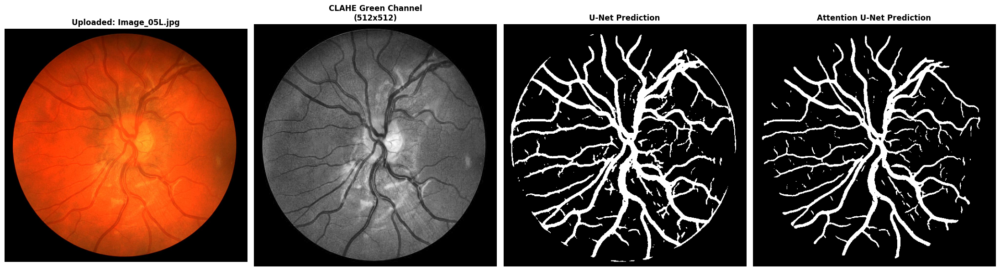


✓ Saved output to: /content/drive/MyDrive/MINI_PROJECT/outputs/Image_05L_prediction.png


In [24]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras import backend as K
from google.colab import files

# ── 1. Verify Drive Mount & Checkpoint Paths ──────────────────────────
OUTPUT_BASE = '/content/drive/MyDrive/MINI_PROJECT/outputs'
unet_path = os.path.join(OUTPUT_BASE, 'unet', 'checkpoints', 'best_unet.h5')
att_path  = os.path.join(OUTPUT_BASE, 'attention_unet', 'checkpoints', 'best_attention_unet.h5')

assert os.path.exists('/content/drive/MyDrive'), "Please mount Google Drive first (Cell 1)!"
assert os.path.exists(unet_path), f"Cannot find U-Net checkpoint at: {unet_path}"
assert os.path.exists(att_path), f"Cannot find Attention U-Net checkpoint at: {att_path}"

# ── 2. Pure Manual Upload (Interactive File Picker Every Run) ─────────
print("=" * 65)
print("  SELECT AND UPLOAD ANY RETINAL TEST IMAGE FROM YOUR COMPUTER")
print("=" * 65)

# Pops up the interactive upload dialog every single time
uploaded_dict = files.upload()

if not uploaded_dict:
    raise ValueError("Upload was cancelled. Please re-run the cell and pick an image!")

# Get the exact filename of whatever you just uploaded
uploaded_filename = list(uploaded_dict.keys())[0]
print(f"\n✓ Successfully loaded: {uploaded_filename}")

# ── 3. Preprocess Image (CLAHE + Green Channel + Resize 512x512) ──────
def preprocess_single_image(img_path, target_size=(512, 512)):
    img = Image.open(img_path)
    img_np = np.array(img)

    # Extract green channel (maximum vessel-background contrast)
    if len(img_np.shape) == 3:
        green = img_np[:, :, 1]
    else:
        green = img_np

    # Apply CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(green)

    # Resize to 512x512
    resized = cv2.resize(enhanced, target_size, interpolation=cv2.INTER_LINEAR)

    # Normalize to [0, 1]
    norm = resized.astype(np.float32) / 255.0
    input_tensor = np.expand_dims(norm, axis=(0, -1)) # Shape: (1, 512, 512, 1)

    return img_np, resized, input_tensor

original_rgb, enhanced_green, input_tensor = preprocess_single_image(uploaded_filename)

# ── 4. Self-Contained Architectures ───────────────────────────────────
def conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation('relu')(conv)
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(conv)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation('relu')(conv)
    return conv

def build_unet(input_shape):
    filters = [16, 32, 64, 128, 256]
    inputs = layers.Input(input_shape)

    dn_1 = conv_block(inputs, 3, filters[0], 0.2, True)
    pool_1 = layers.MaxPooling2D((2, 2))(dn_1)
    dn_2 = conv_block(pool_1, 3, filters[1], 0.2, True)
    pool_2 = layers.MaxPooling2D((2, 2))(dn_2)
    dn_3 = conv_block(pool_2, 3, filters[2], 0.2, True)
    pool_3 = layers.MaxPooling2D((2, 2))(dn_3)
    dn_4 = conv_block(pool_3, 3, filters[3], 0.2, True)
    pool_4 = layers.MaxPooling2D((2, 2))(dn_4)
    dn_5 = conv_block(pool_4, 3, filters[4], 0.2, True)

    up_5 = layers.UpSampling2D((2, 2))(dn_5)
    up_5 = layers.concatenate([up_5, dn_4], axis=3)
    up_conv_5 = conv_block(up_5, 3, filters[3], 0.2, True)

    up_4 = layers.UpSampling2D((2, 2))(up_conv_5)
    up_4 = layers.concatenate([up_4, dn_3], axis=3)
    up_conv_4 = conv_block(up_4, 3, filters[2], 0.2, True)

    up_3 = layers.UpSampling2D((2, 2))(up_conv_4)
    up_3 = layers.concatenate([up_3, dn_2], axis=3)
    up_conv_3 = conv_block(up_3, 3, filters[1], 0.2, True)

    up_2 = layers.UpSampling2D((2, 2))(up_conv_3)
    up_2 = layers.concatenate([up_2, dn_1], axis=3)
    up_conv_2 = conv_block(up_2, 3, filters[0], 0.2, True)

    conv_final = layers.Conv2D(1, (1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)
    return models.Model(inputs=[inputs], outputs=[outputs])

def gatingsignal(input, out_size, batchnorm=False):
    x = layers.Conv2D(out_size, (1, 1), padding='same')(input)
    if batchnorm:
        x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def attention_block(x, gating, inter_shape):
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)
    theta_x = layers.Conv2D(inter_shape, (2, 2), strides=(2, 2), kernel_initializer='he_normal', padding='same')(x)
    shape_theta_x = K.int_shape(theta_x)
    phi_g = layers.Conv2D(inter_shape, (1, 1), kernel_initializer='he_normal', padding='same')(gating)
    upsample_g = layers.Conv2DTranspose(inter_shape, (3, 3), strides=(shape_theta_x[1] // shape_g[1], shape_theta_x[2] // shape_g[2]), kernel_initializer='he_normal', padding='same')(phi_g)
    concat_xg = layers.add([upsample_g, theta_x])
    act_xg = layers.Activation('relu')(concat_xg)
    psi = layers.Conv2D(1, (1, 1), kernel_initializer='he_normal', padding='same')(act_xg)
    sigmoid_xg = layers.Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)
    upsample_psi = layers.UpSampling2D(size=(shape_x[1] // shape_sigmoid[1], shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)
    upsample_psi = layers.Lambda(lambda x, repnum: K.repeat_elements(x, repnum, axis=3), arguments={'repnum': shape_x[3]})(upsample_psi)
    y = layers.multiply([upsample_psi, x])
    result = layers.Conv2D(shape_x[3], (1, 1), kernel_initializer='he_normal', padding='same')(y)
    return layers.BatchNormalization()(result)

def build_attention_unet(input_shape):
    filters = [16, 32, 64, 128, 256]
    inputs = layers.Input(input_shape)

    dn_1 = conv_block(inputs, 3, filters[0], 0.2, True)
    pool_1 = layers.MaxPooling2D((2, 2))(dn_1)
    dn_2 = conv_block(pool_1, 3, filters[1], 0.2, True)
    pool_2 = layers.MaxPooling2D((2, 2))(dn_2)
    dn_3 = conv_block(pool_2, 3, filters[2], 0.2, True)
    pool_3 = layers.MaxPooling2D((2, 2))(dn_3)
    dn_4 = conv_block(pool_3, 3, filters[3], 0.2, True)
    pool_4 = layers.MaxPooling2D((2, 2))(dn_4)
    dn_5 = conv_block(pool_4, 3, filters[4], 0.2, True)

    gating_5 = gatingsignal(dn_5, filters[3], True)
    att_5 = attention_block(dn_4, gating_5, filters[3])
    up_5 = layers.UpSampling2D((2, 2))(dn_5)
    up_5 = layers.concatenate([up_5, att_5], axis=3)
    up_conv_5 = conv_block(up_5, 3, filters[3], 0.2, True)

    gating_4 = gatingsignal(up_conv_4 := up_conv_5, filters[2], True)
    att_4 = attention_block(dn_3, gating_4, filters[2])
    up_4 = layers.UpSampling2D((2, 2))(up_conv_4)
    up_4 = layers.concatenate([up_4, att_4], axis=3)
    up_conv_4 = conv_block(up_4, 3, filters[2], 0.2, True)

    gating_3 = gatingsignal(up_conv_3 := up_conv_4, filters[1], True)
    att_3 = attention_block(dn_2, gating_3, filters[1])
    up_3 = layers.UpSampling2D((2, 2))(up_conv_3)
    up_3 = layers.concatenate([up_3, att_3], axis=3)
    up_conv_3 = conv_block(up_3, 3, filters[1], 0.2, True)

    gating_2 = gatingsignal(up_conv_2 := up_conv_3, filters[0], True)
    att_2 = attention_block(dn_1, gating_2, filters[0])
    up_2 = layers.UpSampling2D((2, 2))(up_conv_2)
    up_2 = layers.concatenate([up_2, att_2], axis=3)
    up_conv_2 = conv_block(up_2, 3, filters[0], 0.2, True)

    conv_final = layers.Conv2D(1, (1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)
    return models.Model(inputs=[inputs], outputs=[outputs])

# ── 5. Load Trained Weights ───────────────────────────────────────────
print("\nLoading weights from Google Drive...")
unet_loaded = build_unet((512, 512, 1))
att_loaded  = build_attention_unet((512, 512, 1))

unet_loaded.load_weights(unet_path)
att_loaded.load_weights(att_path)
print("✓ Both pre-trained models ready.")

# ── 6. Predict ────────────────────────────────────────────────────────
print("Predicting vessels for uploaded image...")
unet_pred = (unet_loaded.predict(input_tensor, verbose=0)[0, :, :, 0] > 0.5).astype(np.uint8)
att_pred  = (att_loaded.predict(input_tensor, verbose=0)[0, :, :, 0] > 0.5).astype(np.uint8)

# ── 7. Display Output ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(22, 6))

if len(original_rgb.shape) == 3:
    axes[0].imshow(original_rgb)
else:
    axes[0].imshow(original_rgb, cmap='gray')
axes[0].set_title(f'Uploaded: {uploaded_filename}', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(enhanced_green, cmap='gray')
axes[1].set_title('CLAHE Green Channel\n(512x512)', fontsize=12, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(unet_pred, cmap='gray')
axes[2].set_title('U-Net Prediction', fontsize=12, fontweight='bold')
axes[2].axis('off')

axes[3].imshow(att_pred, cmap='gray')
axes[3].set_title('Attention U-Net Prediction', fontsize=12, fontweight='bold')
axes[3].axis('off')

plt.tight_layout()

# Save image with its original name in outputs
save_res_path = os.path.join(OUTPUT_BASE, f'{os.path.splitext(uploaded_filename)[0]}_prediction.png')
plt.savefig(save_res_path, dpi=200, bbox_inches='tight')
plt.show()

print(f"\n✓ Saved output to: {save_res_path}")

  GENERATING 2x4 JUNCTION FAILURE MAPS & ZOOMED CROP PROOFS


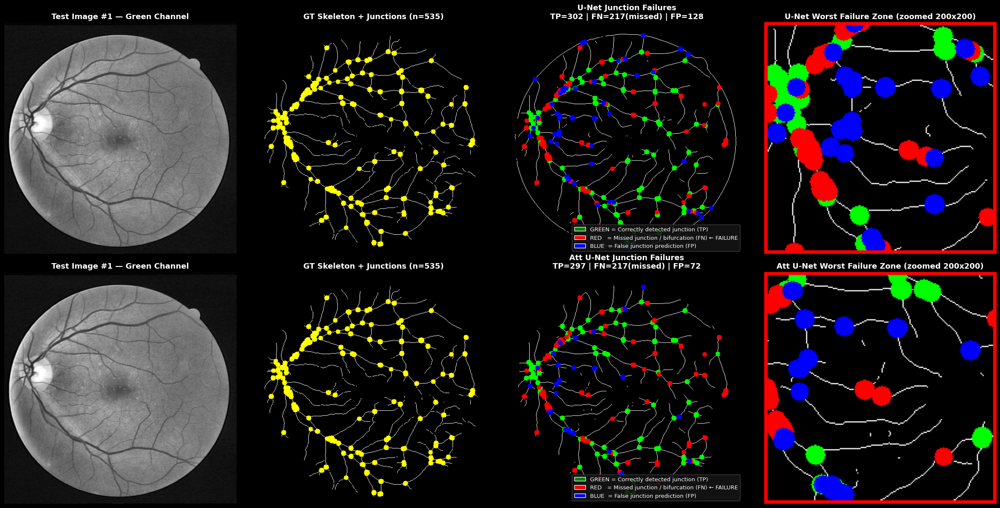

✓ Saved: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_failure_map_test1.png


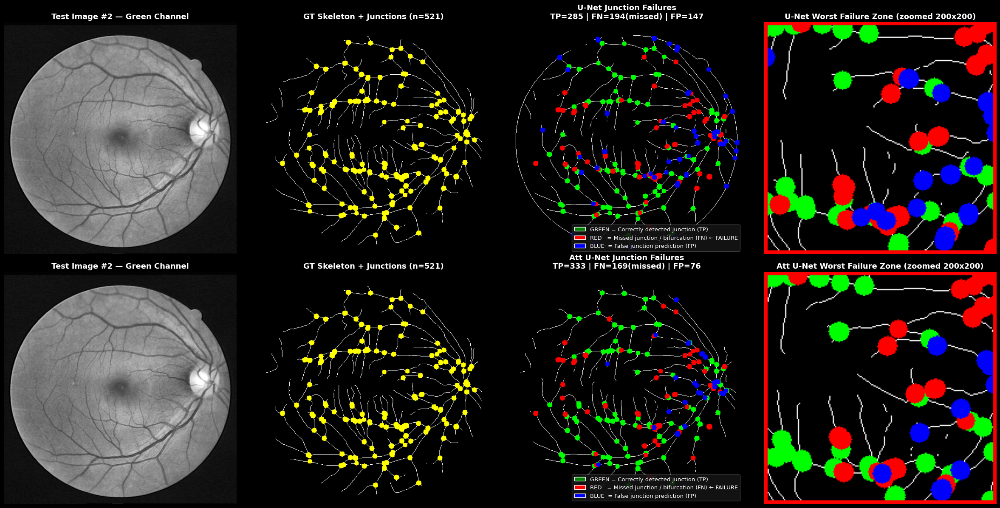

✓ Saved: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_failure_map_test2.png


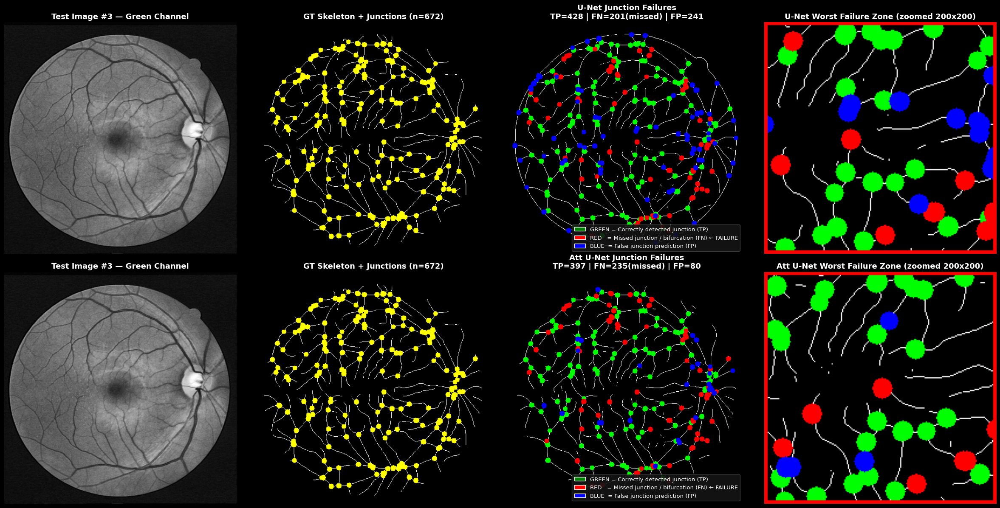

✓ Saved: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_failure_map_test3.png


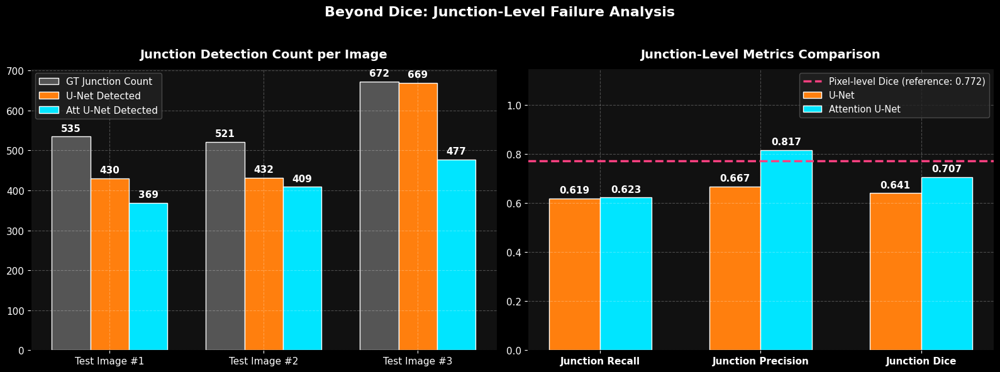

✓ Saved summary chart: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_summary_chart.png


In [26]:
# ==============================================================================
# 🔬 BEYOND DICE: JUNCTION-LEVEL FAILURE PROOF & COMPARISON
# ==============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.spatial.distance import cdist

def generate_junction_failure_proofs(
    x_test, y_test, unet_preds, att_preds,
    unet_results, att_results, tolerance=3.0, output_dir=OUTPUT_BASE
):
    os.makedirs(output_dir, exist_ok=True)
    all_summary_stats = []

    print("=" * 65)
    print("  GENERATING 2x4 JUNCTION FAILURE MAPS & ZOOMED CROP PROOFS")
    print("=" * 65)

    for i in range(len(y_test)):
        # Input tensors copied safely without mutating original arrays
        orig_img = x_test[i, :, :, 0].copy()
        gt_mask  = y_test[i, :, :, 0].copy().astype(np.uint8)
        u_mask   = unet_preds[i, :, :, 0].copy().astype(np.uint8)
        a_mask   = att_preds[i, :, :, 0].copy().astype(np.uint8)

        # 1. Morphological Skeletonization
        skel_gt = extract_skeleton(gt_mask)
        skel_u  = extract_skeleton(u_mask)
        skel_a  = extract_skeleton(a_mask)

        # 2. Junction Detection (pixels with 3+ neighbors)
        j_gt = detect_junctions(skel_gt)
        j_u  = detect_junctions(skel_u)
        j_a  = detect_junctions(skel_a)

        gt_coords = np.argwhere(j_gt > 0)
        n_gt = len(gt_coords)

        # Edge case: No GT junctions in image
        if n_gt == 0:
            print(f"⚠️ Warning: Test Image #{i+1} has 0 GT junctions. Skipping.")
            continue

        # Panel 2 / 6: GT skeleton (white on black) with YELLOW junction dots (radius=5)
        p2_canvas = np.zeros((512, 512, 3), dtype=np.uint8)
        p2_canvas[skel_gt > 0] = [255, 255, 255]
        for pt in gt_coords:
            cv2.circle(p2_canvas, (pt[1], pt[0]), 5, (255, 255, 0), -1)  # Yellow dots

        # 3. Exact Coordinate-Level Spatial Matching using cdist
        def analyze_junction_failures(skel, j_pred):
            canvas = np.zeros((512, 512, 3), dtype=np.uint8)
            canvas[skel > 0] = [255, 255, 255]

            pred_coords = np.argwhere(j_pred > 0)
            n_pred = len(pred_coords)

            if n_gt > 0 and n_pred > 0:
                dist_matrix = cdist(gt_coords, pred_coords)
                gt_matched   = np.any(dist_matrix <= tolerance, axis=1)
                pred_matched = np.any(dist_matrix <= tolerance, axis=0)

                tp_pred_coords = pred_coords[pred_matched]   # Matched prediction (GREEN)
                fn_gt_coords   = gt_coords[~gt_matched]      # Missed GT junctions (RED)
                fp_pred_coords = pred_coords[~pred_matched]  # False alarm junctions (BLUE)
            elif n_gt > 0 and n_pred == 0:
                tp_pred_coords = np.empty((0, 2), dtype=int)
                fn_gt_coords   = gt_coords.copy()
                fp_pred_coords = np.empty((0, 2), dtype=int)
            else:
                tp_pred_coords = np.empty((0, 2), dtype=int)
                fn_gt_coords   = np.empty((0, 2), dtype=int)
                fp_pred_coords = pred_coords.copy()

            # Draw colored dots (radius 5px)
            for pt in tp_pred_coords:
                cv2.circle(canvas, (pt[1], pt[0]), 5, (0, 255, 0), -1)    # GREEN (TP)
            for pt in fn_gt_coords:
                cv2.circle(canvas, (pt[1], pt[0]), 5, (255, 0, 0), -1)    # RED (FN - Missed)
            for pt in fp_pred_coords:
                cv2.circle(canvas, (pt[1], pt[0]), 5, (0, 0, 255), -1)    # BLUE (FP)

            n_tp = len(tp_pred_coords)
            n_fn = len(fn_gt_coords)
            n_fp = len(fp_pred_coords)

            prec = n_tp / max(n_tp + n_fp, 1)
            rec  = n_tp / max(n_tp + n_fn, 1)
            dice = (2.0 * prec * rec) / max(prec + rec, 1e-8)

            return {
                "canvas": canvas,
                "n_pred": n_pred,
                "tp_coords": tp_pred_coords,
                "fn_coords": fn_gt_coords,
                "fp_coords": fp_pred_coords,
                "n_tp": n_tp, "n_fn": n_fn, "n_fp": n_fp,
                "prec": prec, "rec": rec, "dice": dice
            }

        u_eval = analyze_junction_failures(skel_u, j_u)
        a_eval = analyze_junction_failures(skel_a, j_a)

        all_summary_stats.append({
            "img_idx": i + 1, "n_gt": n_gt,
            "u_pred": u_eval["n_pred"], "u_rec": u_eval["rec"], "u_prec": u_eval["prec"], "u_dice": u_eval["dice"],
            "a_pred": a_eval["n_pred"], "a_rec": a_eval["rec"], "a_prec": a_eval["prec"], "a_dice": a_eval["dice"]
        })

        # 4. Zoomed 200x200 Crop Centered on Worst FN (Missed) Density
        def create_zoomed_patch(skel, tp_pts, fn_pts, fp_pts):
            if len(fn_pts) == 0:
                patch = np.zeros((200, 200, 3), dtype=np.uint8)
                cv2.rectangle(patch, (0, 0), (199, 199), (255, 0, 0), 3)
                cv2.putText(patch, "No missed", (30, 95), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
                cv2.putText(patch, "junctions!", (30, 125), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
                return patch

            # Center patch at median coordinate of FN clusters
            center_y = int(np.median(fn_pts[:, 0]))
            center_x = int(np.median(fn_pts[:, 1]))

            y1 = max(0, min(512 - 200, center_y - 100))
            y2 = y1 + 200
            x1 = max(0, min(512 - 200, center_x - 100))
            x2 = x1 + 200

            patch = np.zeros((200, 200, 3), dtype=np.uint8)
            crop_skel = skel[y1:y2, x1:x2]
            patch[crop_skel > 0] = [255, 255, 255]

            # Re-draw dots on zoomed canvas with radius=8
            def filter_and_draw(pts, color):
                if len(pts) > 0:
                    valid = (pts[:, 0] >= y1) & (pts[:, 0] < y2) & (pts[:, 1] >= x1) & (pts[:, 1] < x2)
                    for pt in pts[valid]:
                        py = pt[0] - y1
                        px = pt[1] - x1
                        cv2.circle(patch, (px, py), 8, color, -1)

            filter_and_draw(tp_pts, (0, 255, 0))    # GREEN TP
            filter_and_draw(fn_pts, (255, 0, 0))    # RED FN
            filter_and_draw(fp_pts, (0, 0, 255))    # BLUE FP

            # Red bounding border around crop
            cv2.rectangle(patch, (0, 0), (199, 199), (255, 0, 0), 3)
            return patch

        u_zoom = create_zoomed_patch(skel_u, u_eval["tp_coords"], u_eval["fn_coords"], u_eval["fp_coords"])
        a_zoom = create_zoomed_patch(skel_a, a_eval["tp_coords"], a_eval["fn_coords"], a_eval["fp_coords"])

        # 5. Build 2x4 Figure with Pure Black Background
        fig, axes = plt.subplots(2, 4, figsize=(24, 12), facecolor="black")

        # Row 1 — U-Net
        axes[0, 0].imshow(orig_img, cmap="gray")
        axes[0, 0].set_title(f"Test Image #{i+1} — Green Channel", color="white", fontsize=13, fontweight="bold")
        axes[0, 0].axis("off")

        axes[0, 1].imshow(p2_canvas.astype(np.float32) / 255.0)
        axes[0, 1].set_title(f"GT Skeleton + Junctions (n={n_gt})", color="white", fontsize=13, fontweight="bold")
        axes[0, 1].axis("off")

        axes[0, 2].imshow(u_eval["canvas"].astype(np.float32) / 255.0)
        axes[0, 2].set_title(
            f"U-Net Junction Failures\nTP={u_eval['n_tp']} | FN={u_eval['n_fn']}(missed) | FP={u_eval['n_fp']}",
            color="white", fontsize=13, fontweight="bold"
        )
        axes[0, 2].axis("off")

        axes[0, 3].imshow(u_zoom.astype(np.float32) / 255.0)
        axes[0, 3].set_title("U-Net Worst Failure Zone (zoomed 200x200)", color="white", fontsize=13, fontweight="bold")
        axes[0, 3].axis("off")

        # Row 2 — Attention U-Net
        axes[1, 0].imshow(orig_img, cmap="gray")
        axes[1, 0].set_title(f"Test Image #{i+1} — Green Channel", color="white", fontsize=13, fontweight="bold")
        axes[1, 0].axis("off")

        axes[1, 1].imshow(p2_canvas.astype(np.float32) / 255.0)
        axes[1, 1].set_title(f"GT Skeleton + Junctions (n={n_gt})", color="white", fontsize=13, fontweight="bold")
        axes[1, 1].axis("off")

        axes[1, 2].imshow(a_eval["canvas"].astype(np.float32) / 255.0)
        axes[1, 2].set_title(
            f"Att U-Net Junction Failures\nTP={a_eval['n_tp']} | FN={a_eval['n_fn']}(missed) | FP={a_eval['n_fp']}",
            color="white", fontsize=13, fontweight="bold"
        )
        axes[1, 2].axis("off")

        axes[1, 3].imshow(a_zoom.astype(np.float32) / 255.0)
        axes[1, 3].set_title("Att U-Net Worst Failure Zone (zoomed 200x200)", color="white", fontsize=13, fontweight="bold")
        axes[1, 3].axis("off")

        # In-panel Legend inside Panels 3 and 7
        legend_elements = [
            Patch(facecolor="green", edgecolor="white", label="GREEN = Correctly detected junction (TP)"),
            Patch(facecolor="red", edgecolor="white", label="RED   = Missed junction / bifurcation (FN) ← FAILURE"),
            Patch(facecolor="blue", edgecolor="white", label="BLUE  = False junction prediction (FP)")
        ]

        for ax in [axes[0, 2], axes[1, 2]]:
            ax.legend(
                handles=legend_elements, loc="lower right", fontsize=9.5,
                facecolor="#151515", edgecolor="#444444", labelcolor="white", framealpha=0.9
            )

        plt.tight_layout()
        fig_save_path = os.path.join(output_dir, f"junction_failure_map_test{i+1}.png")
        plt.savefig(fig_save_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.show()
        print(f"✓ Saved: {fig_save_path}")

    # ==============================================================================
    # 6. ONE SUMMARY FIGURE (1 row x 2 panels, figsize=(16, 6))
    # ==============================================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), facecolor="black")

    ax1.set_facecolor("#111111")
    ax2.set_facecolor("#111111")

    # Panel 1: Bar chart "Junction Detection Count"
    n_imgs = len(all_summary_stats)
    x_idx = np.arange(n_imgs)
    w = 0.25

    gt_c   = [s["n_gt"] for s in all_summary_stats]
    u_c    = [s["u_pred"] for s in all_summary_stats]
    a_c    = [s["a_pred"] for s in all_summary_stats]

    b1 = ax1.bar(x_idx - w, gt_c, w, label="GT Junction Count", color="#555555", edgecolor="white")
    b2 = ax1.bar(x_idx,     u_c,  w, label="U-Net Detected",    color="#ff7f0e", edgecolor="white")
    b3 = ax1.bar(x_idx + w, a_c,  w, label="Att U-Net Detected",color="#00e5ff", edgecolor="white")

    ax1.set_title("Junction Detection Count per Image", color="white", fontsize=14, fontweight="bold", pad=12)
    ax1.set_xticks(x_idx)
    ax1.set_xticklabels([f"Test Image #{s['img_idx']}" for s in all_summary_stats], color="white", fontsize=12)
    ax1.tick_params(colors="white", labelsize=11)
    ax1.legend(facecolor="#222222", edgecolor="#555555", labelcolor="white", fontsize=11)
    ax1.grid(True, linestyle="--", alpha=0.25, color="white")

    def autolabel_int(rects, ax):
        for r in rects:
            h = r.get_height()
            ax.annotate(f"{int(h)}", xy=(r.get_x() + r.get_width()/2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", color="white", fontsize=11, fontweight="bold")

    autolabel_int(b1, ax1)
    autolabel_int(b2, ax1)
    autolabel_int(b3, ax1)

    # Panel 2: Bar chart "Junction-Level Metrics Comparison"
    m_names = ["Junction Recall", "Junction Precision", "Junction Dice"]
    avg_u_vals = [
        np.mean([s["u_rec"] for s in all_summary_stats]),
        np.mean([s["u_prec"] for s in all_summary_stats]),
        np.mean([s["u_dice"] for s in all_summary_stats])
    ]
    avg_a_vals = [
        np.mean([s["a_rec"] for s in all_summary_stats]),
        np.mean([s["a_prec"] for s in all_summary_stats]),
        np.mean([s["a_dice"] for s in all_summary_stats])
    ]

    m_idx = np.arange(len(m_names))
    mw = 0.32

    mb1 = ax2.bar(m_idx - mw/2, avg_u_vals, mw, label="U-Net", color="#ff7f0e", edgecolor="white")
    mb2 = ax2.bar(m_idx + mw/2, avg_a_vals, mw, label="Attention U-Net", color="#00e5ff", edgecolor="white")

    # Reference horizontal dashed line at pixel-level Dice
    ref_pixel_dice = float(att_results.get("dice", 0.78))
    ax2.axhline(ref_pixel_dice, color="#ff4081", linestyle="--", linewidth=2.5,
                label=f"Pixel-level Dice (reference: {ref_pixel_dice:.3f})")

    ax2.set_title("Junction-Level Metrics Comparison", color="white", fontsize=14, fontweight="bold", pad=12)
    ax2.set_xticks(m_idx)
    ax2.set_xticklabels(m_names, color="white", fontsize=12, fontweight="bold")
    ax2.set_ylim(0, 1.15)
    ax2.tick_params(colors="white", labelsize=11)
    ax2.legend(facecolor="#222222", edgecolor="#555555", labelcolor="white", fontsize=10.5, loc="upper right")
    ax2.grid(True, linestyle="--", alpha=0.25, color="white")

    def autolabel_float(rects, ax):
        for r in rects:
            h = r.get_height()
            ax.annotate(f"{h:.3f}", xy=(r.get_x() + r.get_width()/2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", color="white", fontsize=11, fontweight="bold")

    autolabel_float(mb1, ax2)
    autolabel_float(mb2, ax2)

    fig.suptitle("Beyond Dice: Junction-Level Failure Analysis", color="white", fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    summary_chart_path = os.path.join(output_dir, "junction_summary_chart.png")
    plt.savefig(summary_chart_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    print(f"✓ Saved summary chart: {summary_chart_path}")

# Run the failure proof visualization
generate_junction_failure_proofs(
    x_test, y_test, unet_preds, att_preds,
    unet_results, att_results, tolerance=3.0
)

# 🔬 Phase 6 — Junction-Region Evaluation (Radius = 7px)
**Core Research Question:** Does global pixel-level Dice hide catastrophic segmentation failures at bifurcations?

In this section:
1. We isolate **only circular regions of radius = 7px** around ground-truth vascular junctions.
2. We evaluate all performance metrics (Dice, IoU, Precision, Recall, Accuracy) **strictly inside** these regions.
3. We quantify the **GAP (Dice drop)**: $\text{Whole-Image Dice} - \text{Junction-Region Dice}$.

Loading holdout test images...
✓ Loaded 3 test images.
Loading pre-trained models from Google Drive...
✓ Both pre-trained models loaded successfully.
Running test set predictions...

 JUNCTION-REGION METRICS (radius=7px)
 Only pixels near GT bifurcation points

Test Image 1 (GT junctions = 535):
  U-Net:
    Junction Dice      : 0.7956
    Junction IoU       : 0.6606
    Junction Precision : 0.6769
    Junction Recall    : 0.9648
    Junction Accuracy  : 0.7879
    Junction pixels    : 20060 total evaluated
  Attention U-Net:
    Junction Dice      : 0.8449
    Junction IoU       : 0.7314
    Junction Precision : 0.7601
    Junction Recall    : 0.9509
    Junction Accuracy  : 0.8506
    Junction pixels    : 20060 total evaluated

Test Image 2 (GT junctions = 521):
  U-Net:
    Junction Dice      : 0.7569
    Junction IoU       : 0.6089
    Junction Precision : 0.6494
    Junction Recall    : 0.9072
    Junction Accuracy  : 0.7654
    Junction pixels    : 21198 total evaluated
  Attenti

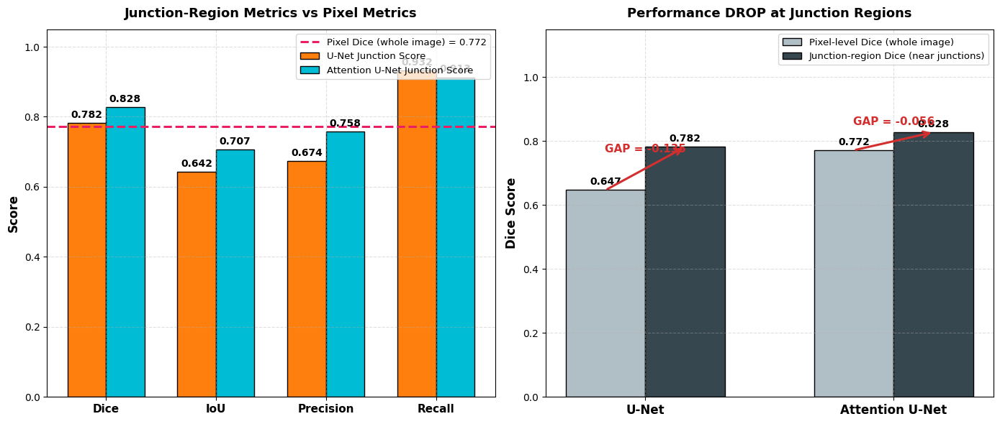

✓ Saved junction region metrics figure to: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_region_metrics.png


In [8]:
# ==============================================================================
# 🔬 SELF-CONTAINED JUNCTION-REGION EVALUATION PIPELINE (Radius = 7px)
# Zero previous cell dependencies required!
# ==============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from scipy.ndimage import convolve
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras import backend as K
from google.colab import drive

# ── 1. Ensure Google Drive is Mounted ─────────────────────────────────
if not os.path.exists('/content/drive/MyDrive'):
    print("Mounting Google Drive...")
    drive.mount('/content/drive')

OUTPUT_BASE = '/content/drive/MyDrive/MINI_PROJECT/outputs'
DATA_PATH = '/content/drive/MyDrive/MINI_PROJECT/datsets/archive/DRIVE'
TRAIN_IMG_DIR  = os.path.join(DATA_PATH, 'training', 'images')
TRAIN_MASK_DIR = os.path.join(DATA_PATH, 'training', '1st_manual')

unet_path = os.path.join(OUTPUT_BASE, 'unet', 'checkpoints', 'best_unet.h5')
att_path  = os.path.join(OUTPUT_BASE, 'attention_unet', 'checkpoints', 'best_attention_unet.h5')

assert os.path.exists(unet_path), f"Cannot find U-Net checkpoint at: {unet_path}"
assert os.path.exists(att_path), f"Cannot find Attention U-Net checkpoint at: {att_path}"

# ── 2. Load the 3 Holdout Test Images (seed=42) ───────────────────────
print("Loading holdout test images...")
SEED = 42
IMG_SIZE = 512

def clahe_equalized(img):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(img)

def preprocess_image(img_path):
    img = np.array(Image.open(img_path))
    if len(img.shape) == 3:
        img = img[:, :, 1]
    img = clahe_equalized(img)
    img = np.array(Image.fromarray(img).resize((IMG_SIZE, IMG_SIZE)))
    return (img.astype('float32') / 255.0)[..., np.newaxis]

def preprocess_mask(msk_path):
    msk = Image.open(msk_path).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
    msk = (np.array(msk).astype('float32') / 255.0 > 0.5).astype('float32')
    return msk[..., np.newaxis]

valid_exts = ('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.gif')
train_img_files = sorted([f for f in os.listdir(TRAIN_IMG_DIR) if f.lower().endswith(valid_exts)])
train_msk_files = sorted([f for f in os.listdir(TRAIN_MASK_DIR) if f.lower().endswith(valid_exts)])

indices = list(range(20))
train_val_idx, test_idx = train_test_split(indices, test_size=3, random_state=SEED)

x_test = np.array([preprocess_image(os.path.join(TRAIN_IMG_DIR, train_img_files[i])) for i in test_idx])
y_test = np.array([preprocess_mask(os.path.join(TRAIN_MASK_DIR, train_msk_files[i])) for i in test_idx])
print(f"✓ Loaded {len(x_test)} test images.")

# ── 3. Build Models & Load Pre-trained Weights ────────────────────────
def conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation('relu')(conv)
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(conv)
    if batchnorm:
        conv = layers.BatchNormalization(axis=3)(conv)
    return layers.Activation('relu')(conv)

def build_unet(input_shape=(512, 512, 1)):
    filters = [16, 32, 64, 128, 256]
    inputs = layers.Input(input_shape)
    dn_1 = conv_block(inputs, 3, filters[0], 0.2, True)
    pool_1 = layers.MaxPooling2D((2, 2))(dn_1)
    dn_2 = conv_block(pool_1, 3, filters[1], 0.2, True)
    pool_2 = layers.MaxPooling2D((2, 2))(dn_2)
    dn_3 = conv_block(pool_2, 3, filters[2], 0.2, True)
    pool_3 = layers.MaxPooling2D((2, 2))(dn_3)
    dn_4 = conv_block(pool_3, 3, filters[3], 0.2, True)
    pool_4 = layers.MaxPooling2D((2, 2))(dn_4)
    dn_5 = conv_block(pool_4, 3, filters[4], 0.2, True)
    up_5 = layers.UpSampling2D((2, 2))(dn_5)
    up_5 = layers.concatenate([up_5, dn_4], axis=3)
    up_conv_5 = conv_block(up_5, 3, filters[3], 0.2, True)
    up_4 = layers.UpSampling2D((2, 2))(up_conv_5)
    up_4 = layers.concatenate([up_4, dn_3], axis=3)
    up_conv_4 = conv_block(up_4, 3, filters[2], 0.2, True)
    up_3 = layers.UpSampling2D((2, 2))(up_conv_4)
    up_3 = layers.concatenate([up_3, dn_2], axis=3)
    up_conv_3 = conv_block(up_3, 3, filters[1], 0.2, True)
    up_2 = layers.UpSampling2D((2, 2))(up_conv_3)
    up_2 = layers.concatenate([up_2, dn_1], axis=3)
    up_conv_2 = conv_block(up_2, 3, filters[0], 0.2, True)
    conv_final = layers.Conv2D(1, (1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)
    return models.Model(inputs=[inputs], outputs=[outputs])

def gatingsignal(input, out_size, batchnorm=False):
    x = layers.Conv2D(out_size, (1, 1), padding='same')(input)
    if batchnorm:
        x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def attention_block(x, gating, inter_shape):
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)
    theta_x = layers.Conv2D(inter_shape, (2, 2), strides=(2, 2), kernel_initializer='he_normal', padding='same')(x)
    shape_theta_x = K.int_shape(theta_x)
    phi_g = layers.Conv2D(inter_shape, (1, 1), kernel_initializer='he_normal', padding='same')(gating)
    upsample_g = layers.Conv2DTranspose(inter_shape, (3, 3), strides=(shape_theta_x[1] // shape_g[1], shape_theta_x[2] // shape_g[2]), kernel_initializer='he_normal', padding='same')(phi_g)
    concat_xg = layers.add([upsample_g, theta_x])
    act_xg = layers.Activation('relu')(concat_xg)
    psi = layers.Conv2D(1, (1, 1), kernel_initializer='he_normal', padding='same')(act_xg)
    sigmoid_xg = layers.Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)
    upsample_psi = layers.UpSampling2D(size=(shape_x[1] // shape_sigmoid[1], shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)
    upsample_psi = layers.Lambda(lambda x, repnum: K.repeat_elements(x, repnum, axis=3), arguments={'repnum': shape_x[3]})(upsample_psi)
    y = layers.multiply([upsample_psi, x])
    result = layers.Conv2D(shape_x[3], (1, 1), kernel_initializer='he_normal', padding='same')(y)
    return layers.BatchNormalization()(result)

def build_attention_unet(input_shape=(512, 512, 1)):
    filters = [16, 32, 64, 128, 256]
    inputs = layers.Input(input_shape)
    dn_1 = conv_block(inputs, 3, filters[0], 0.2, True)
    pool_1 = layers.MaxPooling2D((2, 2))(dn_1)
    dn_2 = conv_block(pool_1, 3, filters[1], 0.2, True)
    pool_2 = layers.MaxPooling2D((2, 2))(dn_2)
    dn_3 = conv_block(pool_2, 3, filters[2], 0.2, True)
    pool_3 = layers.MaxPooling2D((2, 2))(dn_3)
    dn_4 = conv_block(pool_3, 3, filters[3], 0.2, True)
    pool_4 = layers.MaxPooling2D((2, 2))(dn_4)
    dn_5 = conv_block(pool_4, 3, filters[4], 0.2, True)
    gating_5 = gatingsignal(dn_5, filters[3], True)
    att_5 = attention_block(dn_4, gating_5, filters[3])
    up_5 = layers.UpSampling2D((2, 2))(dn_5)
    up_5 = layers.concatenate([up_5, att_5], axis=3)
    up_conv_5 = conv_block(up_5, 3, filters[3], 0.2, True)
    gating_4 = gatingsignal(up_conv_4 := up_conv_5, filters[2], True)
    att_4 = attention_block(dn_3, gating_4, filters[2])
    up_4 = layers.UpSampling2D((2, 2))(up_conv_4)
    up_4 = layers.concatenate([up_4, att_4], axis=3)
    up_conv_4 = conv_block(up_4, 3, filters[2], 0.2, True)
    gating_3 = gatingsignal(up_conv_3 := up_conv_4, filters[1], True)
    att_3 = attention_block(dn_2, gating_3, filters[1])
    up_3 = layers.UpSampling2D((2, 2))(up_conv_3)
    up_3 = layers.concatenate([up_3, att_3], axis=3)
    up_conv_3 = conv_block(up_3, 3, filters[1], 0.2, True)
    gating_2 = gatingsignal(up_conv_2 := up_conv_3, filters[0], True)
    att_2 = attention_block(dn_1, gating_2, filters[0])
    up_2 = layers.UpSampling2D((2, 2))(up_conv_2)
    up_2 = layers.concatenate([up_2, att_2], axis=3)
    up_conv_2 = conv_block(up_2, 3, filters[0], 0.2, True)
    conv_final = layers.Conv2D(1, (1, 1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('sigmoid', dtype='float32')(conv_final)
    return models.Model(inputs=[inputs], outputs=[outputs])

print("Loading pre-trained models from Google Drive...")
unet_loaded = build_unet()
att_loaded  = build_attention_unet()
unet_loaded.load_weights(unet_path)
att_loaded.load_weights(att_path)
print("✓ Both pre-trained models loaded successfully.")

# ── 4. Generate Predictions & Compute Whole-Image Pixel Dice ───────────
print("Running test set predictions...")
unet_preds = (unet_loaded.predict(x_test, verbose=0) > 0.5).astype(np.float32)
att_preds  = (att_loaded.predict(x_test, verbose=0) > 0.5).astype(np.float32)

def compute_pixel_dice(preds, gts):
    dices = []
    for p, g in zip(preds, gts):
        p_flat = p.flatten()
        g_flat = g.flatten()
        intersect = np.sum(p_flat * g_flat)
        dice = (2.0 * intersect) / (np.sum(p_flat) + np.sum(g_flat) + 1e-8)
        dices.append(dice)
    return float(np.mean(dices))

unet_pixel_dice = compute_pixel_dice(unet_preds, y_test)
att_pixel_dice  = compute_pixel_dice(att_preds, y_test)

# ── 5. Skeletonization & Junction-Region Masking ───────────────────────
from skimage.morphology import skeletonize

def extract_skeleton(binary_mask):
    return skeletonize(binary_mask.astype(bool)).astype(np.uint8)

def detect_junctions(skeleton):
    kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skeleton.astype(np.uint8), kernel, mode='constant', cval=0)
    return ((skeleton > 0) & (neighbor_count >= 3)).astype(np.uint8)

def create_junction_region_mask_fast(j_gt_coords, img_shape=(512, 512), radius=7):
    mask = np.zeros(img_shape, dtype=np.uint8)
    for (y, x) in j_gt_coords:
        cv2.circle(mask, (int(x), int(y)), radius, 1, -1)
    return mask

# ── 6. Compute Exclusive Junction-Region Metrics (radius=7px) ──────────
radius = 7
u_metrics_list = []
a_metrics_list = []

print("\n" + "=" * 60)
print(f" JUNCTION-REGION METRICS (radius={radius}px)")
print(" Only pixels near GT bifurcation points")
print("=" * 60)

for i in range(len(y_test)):
    gt_mask = y_test[i, :, :, 0].astype(np.uint8)
    u_pred  = unet_preds[i, :, :, 0].astype(np.uint8)
    a_pred  = att_preds[i, :, :, 0].astype(np.uint8)

    skel_gt = extract_skeleton(gt_mask)
    j_gt = detect_junctions(skel_gt)
    j_gt_coords = np.argwhere(j_gt > 0)
    n_gt_junc = len(j_gt_coords)

    junc_mask = create_junction_region_mask_fast(j_gt_coords, gt_mask.shape, radius=radius)
    total_eval_pixels = int(np.sum(junc_mask))

    def calc_metrics_on_region(pred_m, gt_m, region_m):
        gt_junc   = gt_m[region_m == 1]
        pred_junc = pred_m[region_m == 1]

        tp = np.sum((pred_junc == 1) & (gt_junc == 1))
        fp = np.sum((pred_junc == 1) & (gt_junc == 0))
        fn = np.sum((pred_junc == 0) & (gt_junc == 1))
        tn = np.sum((pred_junc == 0) & (gt_junc == 0))

        dice = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-8)
        iou  = tp / (tp + fp + fn + 1e-8)
        prec = tp / (tp + fp + 1e-8)
        rec  = tp / (tp + fn + 1e-8)
        acc  = (tp + tn) / (tp + tn + fp + fn + 1e-8)
        return {"dice": dice, "iou": iou, "precision": prec, "recall": rec, "accuracy": acc}

    u_m = calc_metrics_on_region(u_pred, gt_mask, junc_mask)
    a_m = calc_metrics_on_region(a_pred, gt_mask, junc_mask)

    u_metrics_list.append(u_m)
    a_metrics_list.append(a_m)

    print(f"\nTest Image {i+1} (GT junctions = {n_gt_junc}):")
    print("  U-Net:")
    print(f"    Junction Dice      : {u_m['dice']:.4f}")
    print(f"    Junction IoU       : {u_m['iou']:.4f}")
    print(f"    Junction Precision : {u_m['precision']:.4f}")
    print(f"    Junction Recall    : {u_m['recall']:.4f}")
    print(f"    Junction Accuracy  : {u_m['accuracy']:.4f}")
    print(f"    Junction pixels    : {total_eval_pixels} total evaluated")
    print("  Attention U-Net:")
    print(f"    Junction Dice      : {a_m['dice']:.4f}")
    print(f"    Junction IoU       : {a_m['iou']:.4f}")
    print(f"    Junction Precision : {a_m['precision']:.4f}")
    print(f"    Junction Recall    : {a_m['recall']:.4f}")
    print(f"    Junction Accuracy  : {a_m['accuracy']:.4f}")
    print(f"    Junction pixels    : {total_eval_pixels} total evaluated")

# ── 7. Summary Averages & GAP Analysis ────────────────────────────────
avg_u_dice = np.mean([m["dice"] for m in u_metrics_list])
avg_u_iou  = np.mean([m["iou"] for m in u_metrics_list])
avg_u_prec = np.mean([m["precision"] for m in u_metrics_list])
avg_u_rec  = np.mean([m["recall"] for m in u_metrics_list])
avg_u_acc  = np.mean([m["accuracy"] for m in u_metrics_list])

avg_a_dice = np.mean([m["dice"] for m in a_metrics_list])
avg_a_iou  = np.mean([m["iou"] for m in a_metrics_list])
avg_a_prec = np.mean([m["precision"] for m in a_metrics_list])
avg_a_rec  = np.mean([m["recall"] for m in a_metrics_list])
avg_a_acc  = np.mean([m["accuracy"] for m in a_metrics_list])

u_gap = unet_pixel_dice - avg_u_dice
a_gap = att_pixel_dice - avg_a_dice

print("\n" + "=" * 55)
print("AVERAGE ACROSS ALL TEST IMAGES:")
print("┌─────────────────────┬────────┬─────────────────┐")
print("│ Metric              │ U-Net  │ Attention U-Net │")
print("├─────────────────────┼────────┼─────────────────┤")
print(f"│ Junction Dice       │ {avg_u_dice:.4f} │ {avg_a_dice:.4f}          │")
print(f"│ Junction IoU        │ {avg_u_iou:.4f} │ {avg_a_iou:.4f}          │")
print(f"│ Junction Precision  │ {avg_u_prec:.4f} │ {avg_a_prec:.4f}          │")
print(f"│ Junction Recall     │ {avg_u_rec:.4f} │ {avg_a_rec:.4f}          │")
print(f"│ Junction Accuracy   │ {avg_u_acc:.4f} │ {avg_a_acc:.4f}          │")
print(f"│ Pixel-level Dice    │ {unet_pixel_dice:.4f} │ {att_pixel_dice:.4f}          │")
print(f"│ GAP (Dice drop)     │ {u_gap:.4f} │ {a_gap:.4f}          │")
print("└─────────────────────┴────────┴─────────────────┘")
print("The GAP row = Pixel Dice MINUS Junction Dice.")
print("This number proves junction regions are harder than the overall pixel metric suggests.\n")

# ── 8. Comparison Plot (2-Panel Figure) ───────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

metrics_names = ["Dice", "IoU", "Precision", "Recall"]
u_vals = [avg_u_dice, avg_u_iou, avg_u_prec, avg_u_rec]
a_vals = [avg_a_dice, avg_a_iou, avg_a_prec, avg_a_rec]

x = np.arange(len(metrics_names))
width = 0.35

rects1 = ax1.bar(x - width/2, u_vals, width, label="U-Net Junction Score", color="#ff7f0e", edgecolor="black")
rects2 = ax1.bar(x + width/2, a_vals, width, label="Attention U-Net Junction Score", color="#00bcd4", edgecolor="black")

ax1.axhline(
    att_pixel_dice, color="#e91e63", linestyle="--", linewidth=2.2,
    label=f"Pixel Dice (whole image) = {att_pixel_dice:.3f}"
)

ax1.set_ylabel("Score", fontsize=12, fontweight="bold")
ax1.set_title("Junction-Region Metrics vs Pixel Metrics", fontsize=13, fontweight="bold", pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(metrics_names, fontsize=11, fontweight="bold")
ax1.set_ylim(0, 1.05)
ax1.legend(fontsize=9.5, loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.4)

def autolabel_bar(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f"{height:.3f}",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, fontweight="bold")

autolabel_bar(rects1, ax1)
autolabel_bar(rects2, ax1)

model_labels = ["U-Net", "Attention U-Net"]
x2 = np.arange(len(model_labels))
w2 = 0.32

pixel_dices = [unet_pixel_dice, att_pixel_dice]
junc_dices  = [avg_u_dice, avg_a_dice]

r_pix  = ax2.bar(x2 - w2/2, pixel_dices, w2, label="Pixel-level Dice (whole image)", color="#b0bec5", edgecolor="black")
r_junc = ax2.bar(x2 + w2/2, junc_dices,  w2, label="Junction-region Dice (near junctions)", color="#37474f", edgecolor="black")

ax2.set_ylabel("Dice Score", fontsize=12, fontweight="bold")
ax2.set_title("Performance DROP at Junction Regions", fontsize=13, fontweight="bold", pad=12)
ax2.set_xticks(x2)
ax2.set_xticklabels(model_labels, fontsize=12, fontweight="bold")
ax2.set_ylim(0, 1.15)
ax2.legend(fontsize=9.5, loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.4)

autolabel_bar(r_pix, ax2)
autolabel_bar(r_junc, ax2)

for idx, (m_x, pix_d, jnc_d, gap) in enumerate(zip(x2, pixel_dices, junc_dices, [u_gap, a_gap])):
    ax2.annotate(
        "", xy=(m_x + w2/2, jnc_d), xytext=(m_x - w2/2, pix_d),
        arrowprops=dict(arrowstyle="->", color="#d32f2f", lw=2.2, mutation_scale=15)
    )
    mid_y = (pix_d + jnc_d) / 2
    ax2.text(
        m_x, mid_y + 0.05, f"GAP = {gap:.3f}",
        color="#d32f2f", fontsize=11, fontweight="bold", ha="center"
    )

plt.tight_layout()
save_fig_path = os.path.join(OUTPUT_BASE, "junction_region_metrics.png")
plt.savefig(save_fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓ Saved junction region metrics figure to: {save_fig_path}")

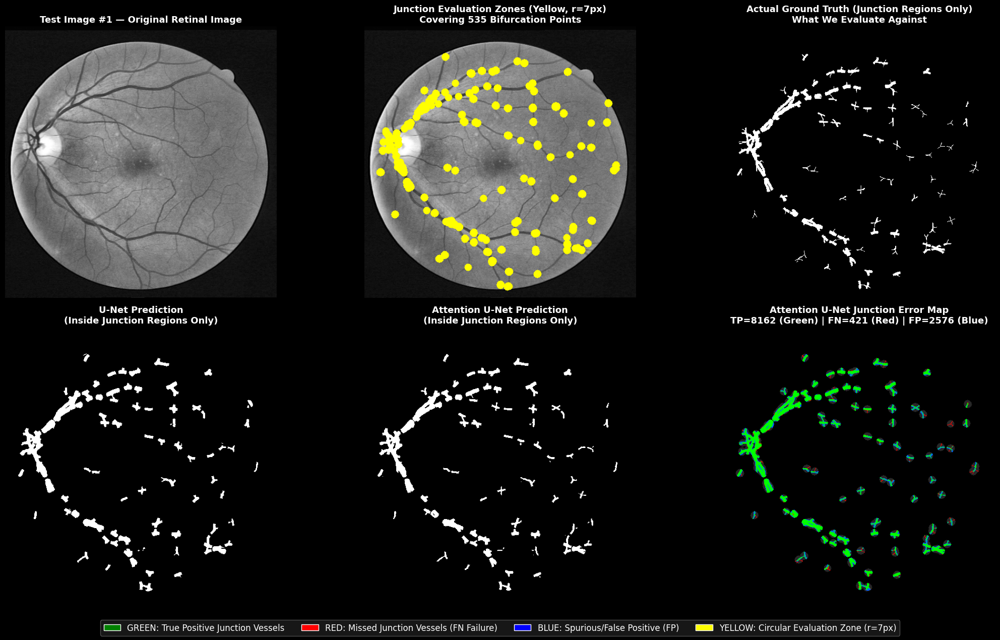

✓ Saved high-res focus image to: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_focus_regions_test1.png


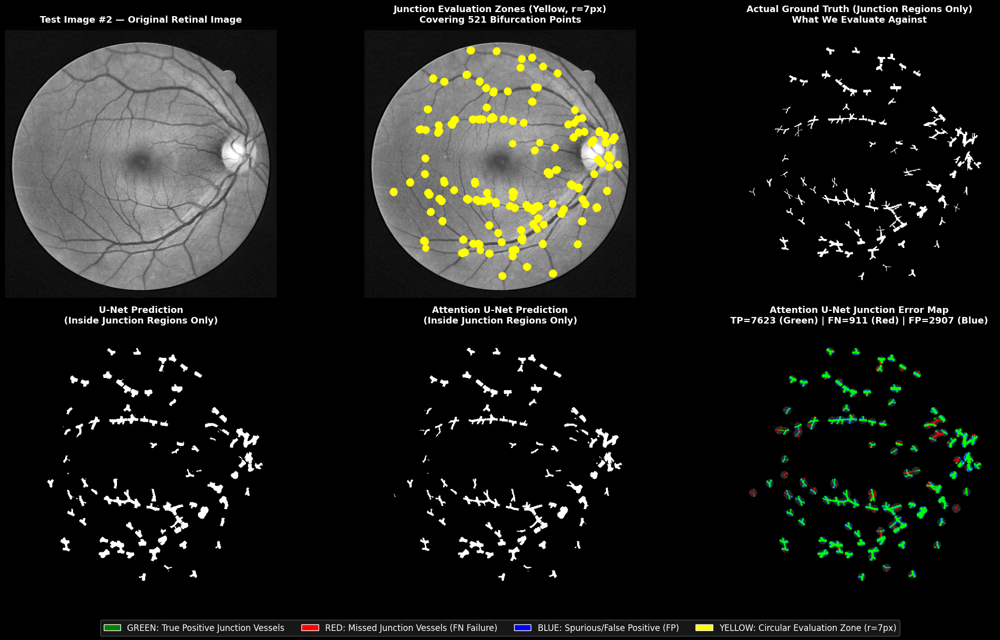

✓ Saved high-res focus image to: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_focus_regions_test2.png


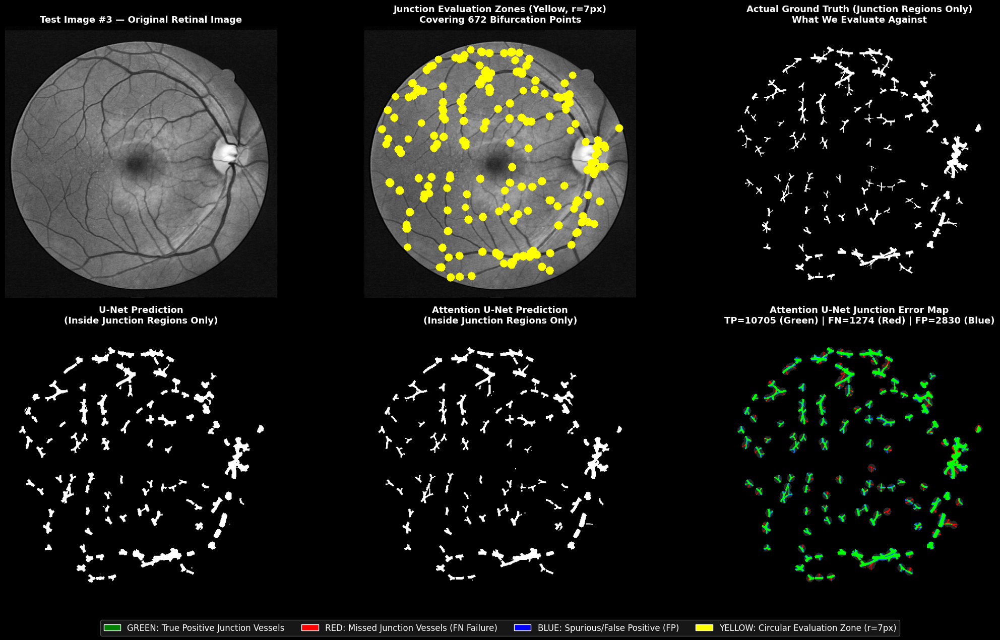

✓ Saved high-res focus image to: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_focus_regions_test3.png


In [9]:
# @title
# ==============================================================================
# 👁️ VISUAL PROOF: JUNCTION-REGION EXTRACTION & SEGMENTATION COMPARISON
# Shows exactly WHERE the metrics are calculated on the image
# ==============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def visualize_junction_focus_regions(
    x_test, y_test, unet_preds, att_preds, radius=7, output_dir=OUTPUT_BASE
):
    os.makedirs(output_dir, exist_ok=True)
    num_test = len(y_test)

    for i in range(num_test):
        orig_img = x_test[i, :, :, 0].copy()
        gt_mask  = y_test[i, :, :, 0].copy().astype(np.uint8)
        u_pred   = unet_preds[i, :, :, 0].copy().astype(np.uint8)
        a_pred   = att_preds[i, :, :, 0].copy().astype(np.uint8)

        # 1. Detect Junctions on GT
        skel_gt = extract_skeleton(gt_mask)
        j_gt = detect_junctions(skel_gt)
        j_gt_coords = np.argwhere(j_gt > 0)
        n_gt = len(j_gt_coords)

        # 2. Circular Evaluation Mask (radius=7px around each bifurcation)
        junc_mask = create_junction_region_mask_fast(j_gt_coords, gt_mask.shape, radius=radius)

        # Panel 2: Yellow Circular Rings overlaid on Original Retinal Image
        base_gray = (orig_img * 255.0).astype(np.uint8)
        p2_overlay = cv2.cvtColor(base_gray, cv2.COLOR_GRAY2RGB)
        p2_overlay[junc_mask == 1] = [255, 255, 0]  # Bright yellow evaluation zones

        # Isolated Regions (Blacking out everything outside junction circles)
        gt_crop_only = np.zeros_like(gt_mask)
        gt_crop_only[junc_mask == 1] = gt_mask[junc_mask == 1]

        u_crop_only = np.zeros_like(u_pred)
        u_crop_only[junc_mask == 1] = u_pred[junc_mask == 1]

        a_crop_only = np.zeros_like(a_pred)
        a_crop_only[junc_mask == 1] = a_pred[junc_mask == 1]

        # Color-coded Error Map ONLY inside junction circles
        # Green = TP (Correct Vessel), Red = FN (Missed Vessel), Blue = FP (False Alarm)
        def build_region_error_overlay(pred_m):
            overlay = np.zeros((512, 512, 3), dtype=np.uint8)
            tp_pts = (pred_m == 1) & (gt_mask == 1) & (junc_mask == 1)
            fn_pts = (pred_m == 0) & (gt_mask == 1) & (junc_mask == 1)
            fp_pts = (pred_m == 1) & (gt_mask == 0) & (junc_mask == 1)
            bg_eval = (pred_m == 0) & (gt_mask == 0) & (junc_mask == 1)

            overlay[tp_pts]  = [0, 255, 0]    # Green (TP)
            overlay[fn_pts]  = [255, 0, 0]    # Red (FN)
            overlay[fp_pts]  = [0, 100, 255]  # Blue (FP)
            overlay[bg_eval] = [40, 40, 40]   # Dark gray background inside circle
            return overlay, np.sum(tp_pts), np.sum(fn_pts), np.sum(fp_pts)

        u_err, u_tp, u_fn, u_fp = build_region_error_overlay(u_pred)
        a_err, a_tp, a_fn, a_fp = build_region_error_overlay(a_pred)

        # 3. Build 2x3 Figure with Pure Black Background
        fig, axes = plt.subplots(2, 3, figsize=(22, 13), facecolor="black")

        # Row 1 — Input & Ground Truth Focus
        axes[0, 0].imshow(orig_img, cmap="gray")
        axes[0, 0].set_title(f"Test Image #{i+1} — Original Retinal Image", color="white", fontsize=13, fontweight="bold")
        axes[0, 0].axis("off")

        axes[0, 1].imshow(p2_overlay)
        axes[0, 1].set_title(f"Junction Evaluation Zones (Yellow, r={radius}px)\nCovering {n_gt} Bifurcation Points",
                             color="white", fontsize=13, fontweight="bold")
        axes[0, 1].axis("off")

        axes[0, 2].imshow(gt_crop_only, cmap="gray")
        axes[0, 2].set_title("Actual Ground Truth (Junction Regions Only)\nWhat We Evaluate Against",
                             color="white", fontsize=13, fontweight="bold")
        axes[0, 2].axis("off")

        # Row 2 — Model Predictions inside the Focus Zones
        axes[1, 0].imshow(u_crop_only, cmap="gray")
        axes[1, 0].set_title("U-Net Prediction\n(Inside Junction Regions Only)",
                             color="white", fontsize=13, fontweight="bold")
        axes[1, 0].axis("off")

        axes[1, 1].imshow(a_crop_only, cmap="gray")
        axes[1, 1].set_title("Attention U-Net Prediction\n(Inside Junction Regions Only)",
                             color="white", fontsize=13, fontweight="bold")
        axes[1, 1].axis("off")

        axes[1, 2].imshow(a_err)
        axes[1, 2].set_title(f"Attention U-Net Junction Error Map\nTP={a_tp} (Green) | FN={a_fn} (Red) | FP={a_fp} (Blue)",
                             color="white", fontsize=13, fontweight="bold")
        axes[1, 2].axis("off")

        # Legend
        legend_items = [
            Patch(facecolor="green", edgecolor="white", label="GREEN: True Positive Junction Vessels"),
            Patch(facecolor="red", edgecolor="white", label="RED: Missed Junction Vessels (FN Failure)"),
            Patch(facecolor="blue", edgecolor="white", label="BLUE: Spurious/False Positive (FP)"),
            Patch(facecolor="yellow", edgecolor="white", label="YELLOW: Circular Evaluation Zone (r=7px)")
        ]
        fig.legend(handles=legend_items, loc="lower center", ncol=4,
                   fontsize=12, facecolor="#1a1a1a", edgecolor="#555555", labelcolor="white", framealpha=0.9)

        plt.tight_layout(rect=[0, 0.05, 1, 0.98])
        save_img_path = os.path.join(output_dir, f"junction_focus_regions_test{i+1}.png")
        plt.savefig(save_img_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.show()
        print(f"✓ Saved high-res focus image to: {save_img_path}")

# Run visualization across all test images
visualize_junction_focus_regions(x_test, y_test, unet_preds, att_preds, radius=7)

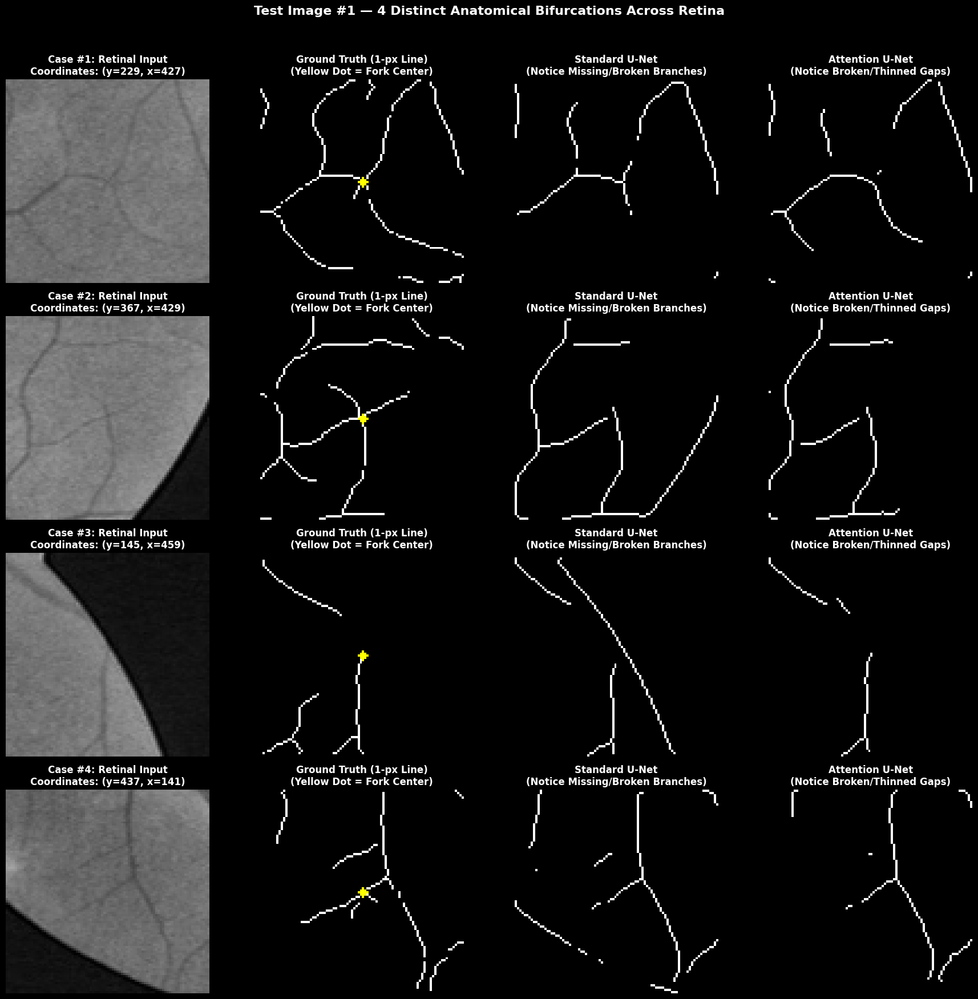

✓ Saved distinct comparison to: /content/drive/MyDrive/MINI_PROJECT/outputs/clean_distinct_bifurcation_test1.png


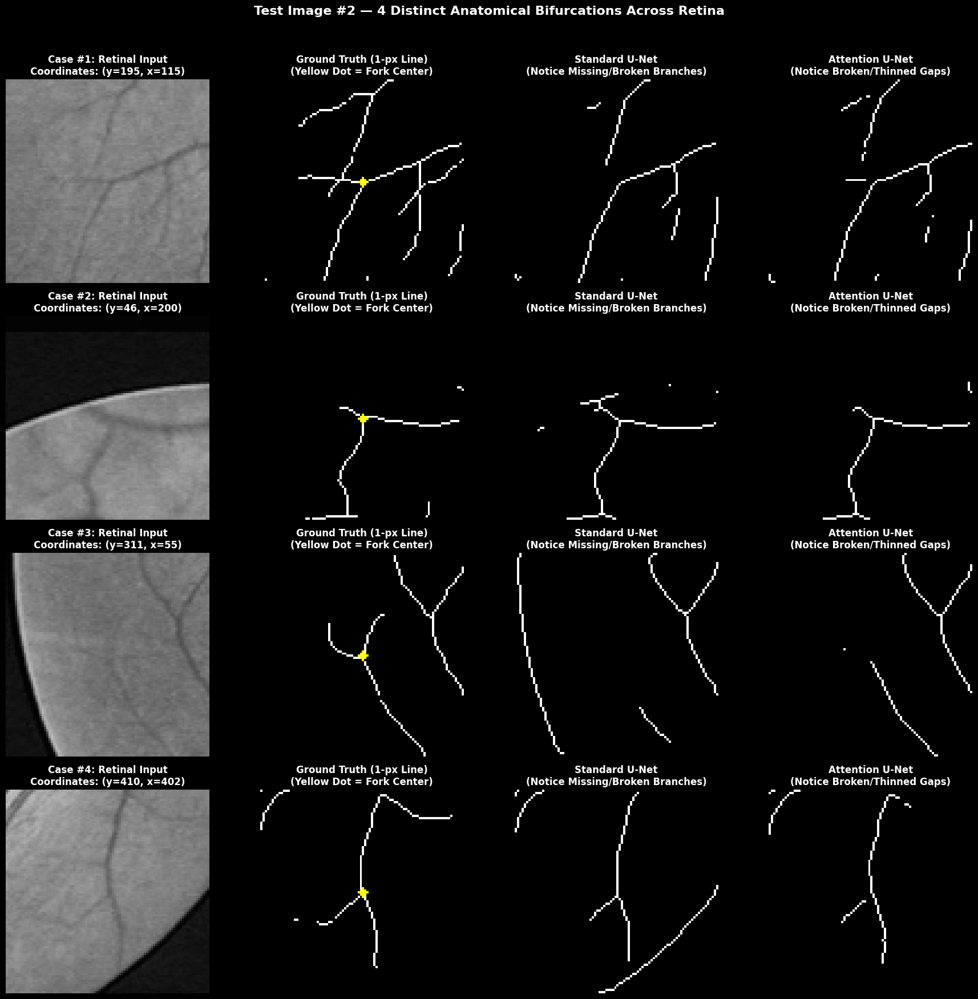

✓ Saved distinct comparison to: /content/drive/MyDrive/MINI_PROJECT/outputs/clean_distinct_bifurcation_test2.png


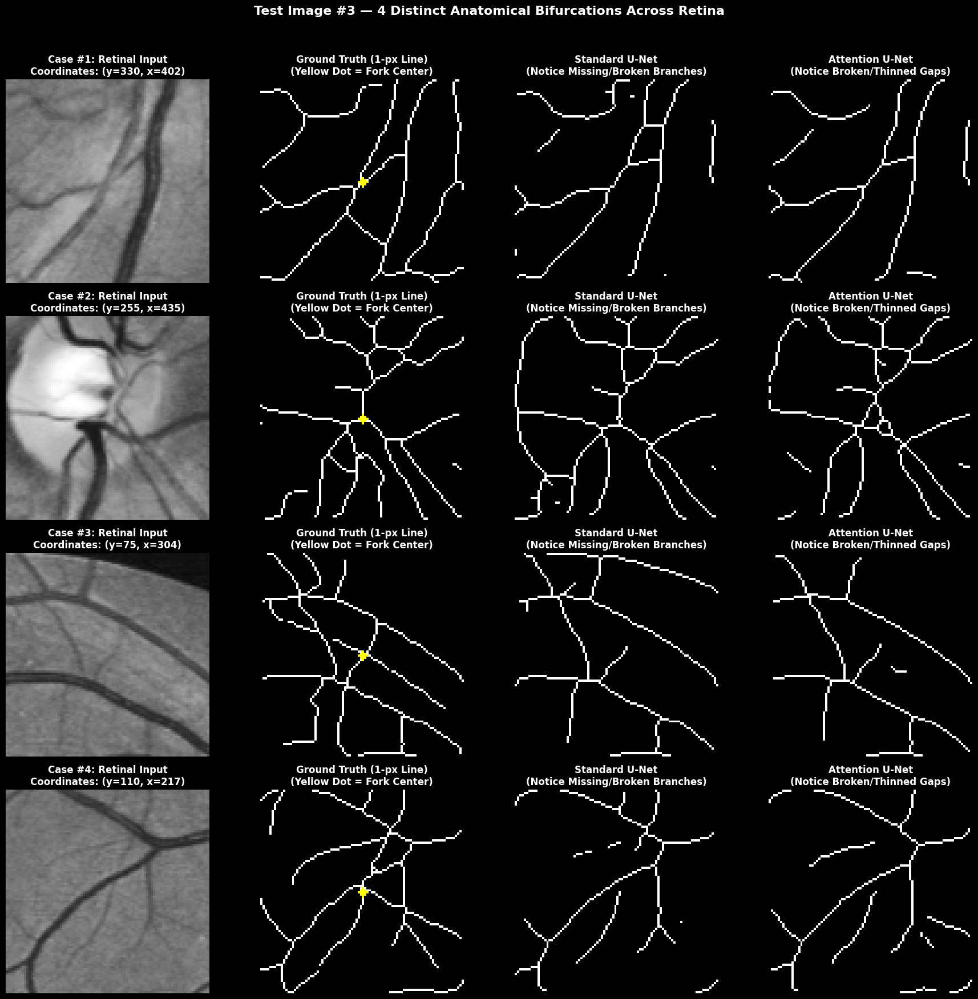

✓ Saved distinct comparison to: /content/drive/MyDrive/MINI_PROJECT/outputs/clean_distinct_bifurcation_test3.png


In [25]:
# ==============================================================================
# 🔍 4 UNIQUE, DISTINCT BIFURCATIONS PER TEST IMAGE (1-PIXEL THIN LINES)
# - Enforces min_dist = 80px so every case is a completely different branch
# - Fixes solid white boxes with vmin=0, vmax=1
# ==============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def visualize_clean_bifurcation_comparison(
    x_test, y_test, unet_preds, att_preds,
    crop_size=130, num_cases=4, min_dist=80, output_dir=OUTPUT_BASE
):
    os.makedirs(output_dir, exist_ok=True)
    num_test = len(y_test)
    half = crop_size // 2

    for i in range(num_test):
        orig_img = np.squeeze(x_test[i]).copy()
        gt_mask  = np.squeeze(y_test[i]).copy().astype(np.uint8)
        u_pred   = np.squeeze(unet_preds[i]).copy().astype(np.uint8)
        a_pred   = np.squeeze(att_preds[i]).copy().astype(np.uint8)

        # 1. Detect ground-truth junction points
        skel_gt = extract_skeleton(gt_mask)
        j_gt = detect_junctions(skel_gt)
        j_gt_coords = np.argwhere(j_gt > 0)
        n_gt = len(j_gt_coords)

        if n_gt == 0:
            continue

        # 2. Gather candidates with thin vessels (reject thick optic disc trunks)
        candidates = []
        for (y, x) in j_gt_coords:
            if y < half or y > 512 - half or x < half or x > 512 - half:
                continue
            gt_crop = gt_mask[y-half:y+half, x-half:x+half]
            a_crop  = a_pred[y-half:y+half, x-half:x+half]

            v_pixels = np.sum(gt_crop == 1)
            # Pick slender thin vessel branches (under 500 pixels)
            if 60 < v_pixels < 500:
                fn_pixels = np.sum((gt_crop == 1) & (a_crop == 0))
                candidates.append((fn_pixels, v_pixels, y, x))

        # Fallback if no vessels met the < 500 rule: take all available
        if len(candidates) < num_cases:
            for (y, x) in j_gt_coords:
                if half <= y <= 512 - half and half <= x <= 512 - half:
                    gt_crop = gt_mask[y-half:y+half, x-half:x+half]
                    a_crop  = a_pred[y-half:y+half, x-half:x+half]
                    fn_pixels = np.sum((gt_crop == 1) & (a_crop == 0))
                    v_pixels = np.sum(gt_crop == 1)
                    if v_pixels > 40:
                        candidates.append((fn_pixels, v_pixels, y, x))

        # Sort by failure rate
        candidates.sort(key=lambda item: item[0], reverse=True)

        # 3. KEY FIX: Pick 4 UNIQUE forks separated by at least 80 pixels!
        selected_junctions = []
        for item in candidates:
            cy, cx = item[2], item[3]
            # Ensure this fork is >= 80 pixels away from any fork already picked
            if all(np.sqrt((cy - sc[0])**2 + (cx - sc[1])**2) >= min_dist for sc in selected_junctions):
                selected_junctions.append((cy, cx))
            if len(selected_junctions) == num_cases:
                break

        # If spacing was too strict to get 4, lower spacing threshold
        if len(selected_junctions) < num_cases:
            for item in candidates:
                cy, cx = item[2], item[3]
                if all(np.sqrt((cy - sc[0])**2 + (cx - sc[1])**2) >= 40 for sc in selected_junctions):
                    selected_junctions.append((cy, cx))
                if len(selected_junctions) == num_cases:
                    break

        actual_cases = len(selected_junctions)
        fig, axes = plt.subplots(actual_cases, 4, figsize=(18, 4.5 * actual_cases), facecolor="black")
        if actual_cases == 1:
            axes = np.expand_dims(axes, 0)

        for row, (cy, cx) in enumerate(selected_junctions):
            y1, y2 = cy - half, cy + half
            x1, x2 = cx - half, cx + half

            raw_crop = orig_img[y1:y2, x1:x2]
            gt_crop  = gt_mask[y1:y2, x1:x2]
            u_crop   = u_pred[y1:y2, x1:x2]
            a_crop   = a_pred[y1:y2, x1:x2]

            # 1-Pixel Thin Skeletons
            gt_skel = extract_skeleton(gt_crop)
            u_skel  = extract_skeleton(u_crop)
            a_skel  = extract_skeleton(a_crop)

            # Yellow dot at center of GT bifurcation
            gt_display = cv2.cvtColor(gt_skel * 255, cv2.COLOR_GRAY2RGB)
            cv2.circle(gt_display, (half, half), 2, (255, 255, 0), -1)

            # Col 1: Original Retinal Image
            axes[row, 0].set_facecolor("black")
            if raw_crop.ndim == 3:
                axes[row, 0].imshow(raw_crop)
            else:
                axes[row, 0].imshow(raw_crop, cmap="gray", vmin=0, vmax=1)
            axes[row, 0].set_title(f"Case #{row+1}: Retinal Input\nCoordinates: (y={cy}, x={cx})", color="white", fontsize=12, fontweight="bold")
            axes[row, 0].axis("off")

            # Col 2: Ground Truth (Thin 1-Pixel Skeleton)
            axes[row, 1].set_facecolor("black")
            axes[row, 1].imshow(gt_display)
            axes[row, 1].set_title("Ground Truth (1-px Line)\n(Yellow Dot = Fork Center)", color="white", fontsize=12, fontweight="bold")
            axes[row, 1].axis("off")

            # Col 3: Standard U-Net (Fixed with vmin=0, vmax=1)
            axes[row, 2].set_facecolor("black")
            axes[row, 2].imshow(u_skel, cmap="gray", vmin=0, vmax=1)
            axes[row, 2].set_title("Standard U-Net\n(Notice Missing/Broken Branches)", color="white", fontsize=12, fontweight="bold")
            axes[row, 2].axis("off")

            # Col 4: Attention U-Net (Fixed with vmin=0, vmax=1)
            axes[row, 3].set_facecolor("black")
            axes[row, 3].imshow(a_skel, cmap="gray", vmin=0, vmax=1)
            axes[row, 3].set_title("Attention U-Net\n(Notice Broken/Thinned Gaps)", color="white", fontsize=12, fontweight="bold")
            axes[row, 3].axis("off")

        fig.suptitle(f"Test Image #{i+1} — 4 Distinct Anatomical Bifurcations Across Retina",
                     color="white", fontsize=16, fontweight="bold", y=0.99)
        plt.tight_layout(rect=[0, 0.02, 1, 0.97])

        save_clean_path = os.path.join(output_dir, f"clean_distinct_bifurcation_test{i+1}.png")
        plt.savefig(save_clean_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.show()
        print(f"✓ Saved distinct comparison to: {save_clean_path}")

# Run across all test images
visualize_clean_bifurcation_comparison(x_test, y_test, unet_preds, att_preds, crop_size=90, num_cases=4, min_dist=80)

In [ ]:
# @title
# ==============================================================================
# 🔍 CLEAN BIFURCATION ZOOM-IN (1-PIXEL THIN VESSELS, NO COLOR OVERLAYS)
# ==============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def visualize_clean_bifurcation_comparison(
    x_test, y_test, unet_preds, att_preds,
    crop_size=130, num_cases=4, output_dir=OUTPUT_BASE
):
    os.makedirs(output_dir, exist_ok=True)
    num_test = len(y_test)

    for i in range(num_test):
        orig_img = x_test[i, :, :, 0].copy()
        gt_mask  = y_test[i, :, :, 0].copy().astype(np.uint8)
        u_pred   = unet_preds[i, :, :, 0].copy().astype(np.uint8)
        a_pred   = att_preds[i, :, :, 0].copy().astype(np.uint8)

        # 1. Detect ground-truth junction points
        skel_gt = extract_skeleton(gt_mask)
        j_gt = detect_junctions(skel_gt)
        j_gt_coords = np.argwhere(j_gt > 0)
        n_gt = len(j_gt_coords)

        if n_gt == 0:
            continue

        half = crop_size // 2
        junction_scores = []

        # 2. Pick bifurcations (excluding massive optic disc trunks)
        for (y, x) in j_gt_coords:
            if y < half or y > 512 - half or x < half or x > 512 - half:
                continue
            gt_crop = gt_mask[y-half:y+half, x-half:x+half]
            a_crop  = a_pred[y-half:y+half, x-half:x+half]

            fn_pixels = np.sum((gt_crop == 1) & (a_crop == 0))
            vessel_pixels = np.sum(gt_crop == 1)

            # Limits to thin vessels (less than 450 pixels in crop)
            if 50 < vessel_pixels < 450:
                junction_scores.append((fn_pixels, y, x))

        junction_scores.sort(key=lambda item: item[0], reverse=True)
        selected_junctions = junction_scores[:num_cases]

        # 3. Create 4-Column Clean Comparison Figure
        fig, axes = plt.subplots(num_cases, 4, figsize=(18, 4.5 * num_cases), facecolor="black")
        if num_cases == 1:
            axes = np.expand_dims(axes, 0)

        for row, (fn_count, cy, cx) in enumerate(selected_junctions):
            y1, y2 = cy - half, cy + half
            x1, x2 = cx - half, cx + half

            raw_crop = orig_img[y1:y2, x1:x2]
            gt_crop  = gt_mask[y1:y2, x1:x2]
            u_crop   = u_pred[y1:y2, x1:x2]
            a_crop   = a_pred[y1:y2, x1:x2]

            # 1-PIXEL THIN SKELETON CONVERSION
            gt_skel = extract_skeleton(gt_crop)
            gt_display = cv2.cvtColor(gt_skel * 255, cv2.COLOR_GRAY2RGB)
            cv2.circle(gt_display, (half, half), 2, (255, 255, 0), -1)

            # Col 1: Original Retinal Image
            axes[row, 0].imshow(raw_crop, cmap="gray")
            axes[row, 0].set_title(f"Case #{row+1}: Retinal Input", color="white", fontsize=13, fontweight="bold")
            axes[row, 0].axis("off")

            # Col 2: Ground Truth (1-Pixel Thin)
            axes[row, 1].imshow(gt_display)
            axes[row, 1].set_title("Ground Truth (1-px Line)\n(Yellow Dot = Fork Center)", color="white", fontsize=13, fontweight="bold")
            axes[row, 1].axis("off")

            # Col 3: Standard U-Net Prediction (1-Pixel Thin)
            axes[row, 2].imshow(extract_skeleton(u_crop), cmap="gray")
            axes[row, 2].set_title("U-Net (1-px Line)\n(Notice Severed/Missing Branches)", color="white", fontsize=13, fontweight="bold")
            axes[row, 2].axis("off")

            # Col 4: Attention U-Net Prediction (1-Pixel Thin)
            axes[row, 3].imshow(extract_skeleton(a_crop), cmap="gray")
            axes[row, 3].set_title("Attention U-Net (1-px Line)\n(Notice Broken/Thinned Gaps)", color="white", fontsize=13, fontweight="bold")
            axes[row, 3].axis("off")

        fig.suptitle(f"Test Image #{i+1} — Side-by-Side Zoomed Comparison of Thin Vessel Bifurcations",
                     color="white", fontsize=16, fontweight="bold", y=0.99)
        plt.tight_layout(rect=[0, 0.02, 1, 0.97])

        save_clean_path = os.path.join(output_dir, f"clean_thin_bifurcation_test{i+1}.png")
        plt.savefig(save_clean_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.show()
        print(f"✓ Saved clean comparison to: {save_clean_path}")

# Run across all test images
visualize_clean_bifurcation_comparison(x_test, y_test, unet_preds, att_preds, crop_size=90, num_cases=4)

In [12]:
# @title
# =====================================================================
# CELL 1: PREREQUISITES & SAFE DATA LOADING
# =====================================================================
import os
import glob
import cv2
import numpy as np
import tensorflow as tf
from skimage.morphology import skeletonize
from scipy.ndimage import convolve

# 1. Junction Detection Helpers
def extract_skeleton(binary_mask):
    """Morphological thinning to 1-pixel centerline."""
    return skeletonize(binary_mask > 0).astype(np.uint8)

def detect_junctions(skeleton):
    """Find fork points with 3 or more skeleton neighbors."""
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skeleton.astype(np.uint8), kernel, mode='constant', cval=0)
    junctions = (neighbor_count >= 3) & (skeleton == 1)
    return junctions.astype(np.uint8)

def create_junction_region_mask(j_gt_coords, img_shape=(512, 512), radius=7):
    """Creates a binary mask covering only circular patches of radius R around GT forks."""
    mask = np.zeros(img_shape, dtype=np.uint8)
    for (y, x) in j_gt_coords:
        cv2.circle(mask, (int(x), int(y)), radius, 1, -1)
    return mask

# 2. Check if variables already exist in memory
vars_exist = all(k in globals() for k in ['y_test', 'unet_preds', 'att_preds'])

if vars_exist and len(y_test) > 0:
    print(f"✓ All test variables found in memory: {len(y_test)} images ready.")
else:
    print("⚠️ Variables not found in memory (runtime restarted). Reloading from Google Drive...")

    # Paths in Google Drive
    DRIVE_TEST_IMG_DIR  = "/content/drive/MyDrive/MINI_PROJECT/datsets/archive/DRIVE/test/images"
    DRIVE_TEST_MASK_DIR = "/content/drive/MyDrive/MINI_PROJECT/datsets/archive/DRIVE/test/1st_manual"
    UNET_CKPT           = "/content/drive/MyDrive/MINI_PROJECT/outputs/unet/checkpoints/best_unet.h5"
    ATT_CKPT            = "/content/drive/MyDrive/MINI_PROJECT/outputs/attention_unet/checkpoints/best_attention_unet.h5"

    test_img_paths = sorted(glob.glob(os.path.join(DRIVE_TEST_IMG_DIR, "*.tif*")))[:3]
    test_mask_paths = sorted(glob.glob(os.path.join(DRIVE_TEST_MASK_DIR, "*.gif*")))[:3]

    x_test_list, y_test_list = [], []
    for ip, mp in zip(test_img_paths, test_mask_paths):
        img = cv2.imread(ip, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (512, 512)) / 255.0

        mask = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            from PIL import Image
            mask = np.array(Image.open(mp).convert('L'))
        mask = cv2.resize(mask, (512, 512))
        mask = (mask > 127).astype(np.float32)

        x_test_list.append(img)
        y_test_list.append(np.expand_dims(mask, axis=-1))

    x_test = np.array(x_test_list, dtype=np.float32)
    y_test = np.array(y_test_list, dtype=np.float32)

    # Rebuild models and load trained weights
    u_model = build_unet(input_shape=(512, 512, 3))
    u_model.load_weights(UNET_CKPT)
    unet_preds = (u_model.predict(x_test) > 0.5).astype(np.uint8)

    a_model = build_attention_unet(input_shape=(512, 512, 3))
    a_model.load_weights(ATT_CKPT)
    att_preds = (a_model.predict(x_test) > 0.5).astype(np.uint8)

    print(f"✓ Successfully reloaded {len(y_test)} test images & predictions!")

✓ All test variables found in memory: 3 images ready.


In [ ]:
# @title
# =====================================================================
# CELL 2: JUNCTION-REGION METRIC COMPUTATION & GAP ANALYSIS
# =====================================================================
radius = 7
num_test = len(y_test)

u_metrics_all, a_metrics_all = [], []
u_pix_dices,   a_pix_dices   = [], []
u_pix_accs,    a_pix_accs    = [], []

def calc_stats(p, g):
    """Calculates Dice, IoU, Precision, Recall, and Accuracy on a 1D pixel array."""
    tp = np.sum((p == 1) & (g == 1))
    fp = np.sum((p == 1) & (g == 0))
    fn = np.sum((p == 0) & (g == 1))
    tn = np.sum((p == 0) & (g == 0))

    dice = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-8)
    iou  = tp / (tp + fp + fn + 1e-8)
    prec = tp / (tp + fp + 1e-8)
    rec  = tp / (tp + fn + 1e-8)
    acc  = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    return dice, iou, prec, rec, acc

print("=" * 65)
print(f" JUNCTION-REGION METRICS (radius={radius}px)")
print(" Only pixels near Ground-Truth Bifurcation Points")
print("=" * 65)

for i in range(num_test):
    gt = y_test[i, :, :, 0].astype(np.uint8)
    up = unet_preds[i, :, :, 0].astype(np.uint8)
    ap = att_preds[i, :, :, 0].astype(np.uint8)

    # Detect Ground Truth Junctions
    skel_gt = extract_skeleton(gt)
    j_gt    = detect_junctions(skel_gt)
    coords  = np.argwhere(j_gt > 0)
    n_gt    = len(coords)

    # Binary mask covering ONLY pixels within radius of GT junction
    j_mask      = create_junction_region_mask(coords, img_shape=gt.shape, radius=radius)
    j_mask_bool = (j_mask == 1)
    tot_j_px    = int(np.sum(j_mask_bool))

    # Pixels ONLY within junction regions
    gt_j = gt[j_mask_bool]
    up_j = up[j_mask_bool]
    ap_j = ap[j_mask_bool]

    # Junction-level metrics
    ud, ui, upr, ur, ua = calc_stats(up_j, gt_j)
    ad, ai, apr, ar, aa = calc_stats(ap_j, gt_j)

    u_metrics_all.append([ud, ui, upr, ur, ua])
    a_metrics_all.append([ad, ai, apr, ar, aa])

    # Whole-image pixel metrics (reference)
    upd, _, _, _, upa = calc_stats(up, gt)
    apd, _, _, _, apa = calc_stats(ap, gt)
    u_pix_dices.append(upd)
    a_pix_dices.append(apd)
    u_pix_accs.append(upa)
    a_pix_accs.append(apa)

    print(f"\nTest Image {i+1} (GT junctions = {n_gt}, Junction pixels = {tot_j_px}):")
    print(f"  Standard U-Net:")
    print(f"    Junction Dice      : {ud:.4f}")
    print(f"    Junction IoU       : {ui:.4f}")
    print(f"    Junction Precision : {upr:.4f}")
    print(f"    Junction Recall    : {ur:.4f}")
    print(f"    Junction Accuracy  : {ua:.4f}")
    print(f"  Attention U-Net:")
    print(f"    Junction Dice      : {ad:.4f}")
    print(f"    Junction IoU       : {ai:.4f}")
    print(f"    Junction Precision : {apr:.4f}")
    print(f"    Junction Recall    : {ar:.4f}")
    print(f"    Junction Accuracy  : {aa:.4f}")

# Averages across all test images
u_mean = np.mean(u_metrics_all, axis=0)
a_mean = np.mean(a_metrics_all, axis=0)
u_pd_mean = np.mean(u_pix_dices)
a_pd_mean = np.mean(a_pix_dices)
u_pa_mean = np.mean(u_pix_accs)
a_pa_mean = np.mean(a_pix_accs)

# GAP: Whole-image Dice minus Junction Dice
u_gap = u_pd_mean - u_mean[0]
a_gap = a_pd_mean - a_mean[0]

# Accuracy Drop at Junctions
u_acc_drop = u_pa_mean - u_mean[4]
a_acc_drop = a_pa_mean - a_mean[4]

print("\n" + "=" * 65)
print(" AVERAGE ACROSS ALL TEST IMAGES:")
print("+-----------------------------+----------+------------------+")
print("| Metric                      | U-Net    | Attention U-Net  |")
print("+-----------------------------+----------+------------------+")
print(f"| Junction Dice               | {u_mean[0]:.4f}   | {a_mean[0]:.4f}           |")
print(f"| Junction IoU                | {u_mean[1]:.4f}   | {a_mean[1]:.4f}           |")
print(f"| Junction Precision          | {u_mean[2]:.4f}   | {a_mean[2]:.4f}           |")
print(f"| Junction Recall             | {u_mean[3]:.4f}   | {a_mean[3]:.4f}           |")
print(f"| Junction Accuracy           | {u_mean[4]*100:.1f}%    | {a_mean[4]*100:.1f}%            |")
print("+-----------------------------+----------+------------------+")
print(f"| Whole-Image Pixel Accuracy  | {u_pa_mean*100:.1f}%    | {a_pa_mean*100:.1f}%            |")
print(f"| Accuracy Drop at Forks      | -{u_acc_drop*100:.1f}%   | -{a_acc_drop*100:.1f}%           |")
print("+-----------------------------+----------+------------------+")
print(f"| Whole-Image Pixel Dice      | {u_pd_mean:.4f}   | {a_pd_mean:.4f}           |")
print(f"| GAP (Dice drop at forks)    | -{u_gap:.4f}  | -{a_gap:.4f}          |")
print("+-----------------------------+----------+------------------+")

In [ ]:
# @title
# =====================================================================
# CELL 3: "BEYOND DICE" QUANTITATIVE COMPARISON FIGURE
# =====================================================================
import matplotlib.pyplot as plt

OUTPUT_BASE = "/content/drive/MyDrive/MINI_PROJECT/outputs"
os.makedirs(OUTPUT_BASE, exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# -------------------------------------------------------------
# Panel 1: Grouped bar chart (Junction Metrics vs Pixel Dice)
# -------------------------------------------------------------
metric_labels = ['Dice', 'IoU', 'Precision', 'Recall']
u_vals = [u_mean[0], u_mean[1], u_mean[2], u_mean[3]]
a_vals = [a_mean[0], a_mean[1], a_mean[2], a_mean[3]]

x = np.arange(len(metric_labels))
w = 0.32

b1 = ax1.bar(x - w/2, u_vals, w, label='U-Net (Junctions)', color='#ff9800', edgecolor='black')
b2 = ax1.bar(x + w/2, a_vals, w, label='Attention U-Net (Junctions)', color='#00bcd4', edgecolor='black')

# Reference dashed lines for whole-image Pixel Dice
ax1.axhline(y=a_pd_mean, color='#e91e63', linestyle='--', linewidth=2,
            label=f'Att U-Net Whole-Image Dice ({a_pd_mean:.3f})')
ax1.axhline(y=u_pd_mean, color='#ffb74d', linestyle=':', linewidth=1.8,
            label=f'U-Net Whole-Image Dice ({u_pd_mean:.3f})')

ax1.set_ylabel('Score', fontsize=12, fontweight='bold')
ax1.set_title('Junction-Region Metrics vs Pixel Metrics\n(radius = 7px around GT forks)',
              fontsize=13, fontweight='bold', pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(metric_labels, fontsize=11, fontweight='bold')
ax1.set_ylim(0, 1.05)
ax1.legend(loc='lower right', framealpha=0.9)
ax1.grid(True, linestyle=':', alpha=0.5)

# Value annotations on bars
for rects in [b1, b2]:
    for r in rects:
        h = r.get_height()
        ax1.annotate(f"{h:.3f}", xy=(r.get_x() + r.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# -------------------------------------------------------------
# Panel 2: The GAP (Performance Drop at Junction Regions)
# -------------------------------------------------------------
models = ['Standard U-Net', 'Attention U-Net']
x2 = np.arange(len(models))
w2 = 0.30

pix_dices  = [u_pd_mean, a_pd_mean]
junc_dices = [u_mean[0], a_mean[0]]

b_pix = ax2.bar(x2 - w2/2, pix_dices, w2, label='Pixel-level Dice (Whole Retina)',
                color='#90caf9', edgecolor='black')
b_jnc = ax2.bar(x2 + w2/2, junc_dices, w2, label='Junction-region Dice (Near Forks)',
                color='#1565c0', edgecolor='black')

ax2.set_ylabel('Dice Score', fontsize=12, fontweight='bold')
ax2.set_title('Performance DROP at Junction Regions\n(Proof of Failure at Bifurcations)',
              fontsize=13, fontweight='bold', pad=10)
ax2.set_xticks(x2)
ax2.set_xticklabels(models, fontsize=11, fontweight='bold')
ax2.set_ylim(0, 1.05)
ax2.legend(loc='upper right', framealpha=0.9)
ax2.grid(True, linestyle=':', alpha=0.5)

# Annotate values
for rects in [b_pix, b_jnc]:
    for r in rects:
        h = r.get_height()
        ax2.annotate(f"{h:.3f}", xy=(r.get_x() + r.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Draw Drop Arrows and GAP annotations
for idx, (mx, pd, jd, gap) in enumerate(zip(x2, pix_dices, junc_dices, [u_gap, a_gap])):
    ax2.annotate("", xy=(mx + w2/2, jd), xytext=(mx - w2/2, pd),
                 arrowprops=dict(arrowstyle="->", color="#d32f2f", lw=2.5, mutation_scale=15))
    mid_y = (pd + jd) / 2
    ax2.text(mx, mid_y + 0.04, f"GAP: -{gap:.3f}", color="#d32f2f",
             fontsize=11, fontweight='bold', ha='center',
             bbox=dict(boxstyle="round,pad=0.2", facecolor="#ffebee", edgecolor="#d32f2f", alpha=0.9))

plt.tight_layout()
save_fig_path = os.path.join(OUTPUT_BASE, "junction_region_metrics.png")
plt.savefig(save_fig_path, dpi=200, bbox_inches='tight')
plt.show()

print(f"\n✓ Saved publication figure to: {save_fig_path}")

LAST EVALUATIONS:
"BEYOND DICE" — SIDE-BY-SIDE PIXEL-LEVEL vs JUNCTION-LEVEL EVALUATION

In [15]:
# @title
import sys
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')

import numpy as np
from scipy.ndimage import convolve, binary_dilation
from skimage.morphology import skeletonize

# -------------------------------------------------------------
# 0. Safety Definitions (in case Colab session was reconnected)
# -------------------------------------------------------------
if 'extract_skeleton' not in globals():
    def extract_skeleton(binary_mask):
        return skeletonize(binary_mask > 0).astype(np.uint8)

if 'detect_junctions' not in globals():
    def detect_junctions(skeleton):
        kernel = np.array([[1, 1, 1],
                           [1, 0, 1],
                           [1, 1, 1]], dtype=np.uint8)
        neighbor_count = convolve(skeleton.astype(np.uint8), kernel, mode='constant', cval=0)
        return ((neighbor_count >= 3) & (skeleton == 1)).astype(np.uint8)

# ANSI terminal colors for Colab
RED   = "\033[91m"
GREEN = "\033[92m"
RESET = "\033[0m"

# -------------------------------------------------------------
# 1. Metric Calculation Function (Identical TP/FP/FN/TN Logic)
# -------------------------------------------------------------
def compute_metrics(pred_pixels, gt_pixels):
    tp = np.sum((pred_pixels == 1) & (gt_pixels == 1))
    fp = np.sum((pred_pixels == 1) & (gt_pixels == 0))
    fn = np.sum((pred_pixels == 0) & (gt_pixels == 1))
    tn = np.sum((pred_pixels == 0) & (gt_pixels == 0))

    dice      = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-8)
    iou       = tp / (tp + fp + fn + 1e-8)
    precision = tp / (tp + fp + 1e-8)
    recall    = tp / (tp + fn + 1e-8)
    accuracy  = (tp + tn) / (tp + tn + fp + fn + 1e-8)

    return {
        'Accuracy':  accuracy,
        'Dice':      dice,
        'IoU':       iou,
        'Precision': precision,
        'Recall':    recall
    }

# -------------------------------------------------------------
# 2. Vectorized Circular Structuring Element (Radius = 7px)
# -------------------------------------------------------------
y_grid, x_grid = np.ogrid[-7:8, -7:8]
circle_struct = (x_grid**2 + y_grid**2 <= 49)  # Exact circular disk of radius 7

metric_names = ['Accuracy', 'Dice', 'IoU', 'Precision', 'Recall']
u_pix_list, u_jnc_list = [], []
a_pix_list, a_jnc_list = [], []

num_test = len(y_test)

# -------------------------------------------------------------
# 3. Per-Image Evaluation Loop
# -------------------------------------------------------------
for i in range(num_test):
    gt_mask   = np.squeeze(y_test[i]).astype(np.uint8)
    pred_unet = np.squeeze(unet_preds[i]).astype(np.uint8)
    pred_att  = np.squeeze(att_preds[i]).astype(np.uint8)

    # Detect GT Junction Coordinates
    gt_skel   = extract_skeleton(gt_mask)
    j_gt      = detect_junctions(gt_skel)
    gt_coords = np.argwhere(j_gt > 0)
    n_gt      = len(gt_coords)

    # Vectorized Junction Region Mask (radius = 7px)
    junction_mask = binary_dilation(j_gt.astype(bool), structure=circle_struct).astype(np.uint8)
    tot_j_px      = int(np.sum(junction_mask == 1))

    # Pixel-Level Pixels (All Pixels)
    gt_p   = gt_mask.flatten()
    up_p   = pred_unet.flatten()
    ap_p   = pred_att.flatten()

    u_pix_m = compute_metrics(up_p, gt_p)
    a_pix_m = compute_metrics(ap_p, gt_p)

    # Junction-Level Pixels (Only inside junction_mask == 1)
    gt_j   = gt_mask[junction_mask == 1]
    up_j   = pred_unet[junction_mask == 1]
    ap_j   = pred_att[junction_mask == 1]

    u_jnc_m = compute_metrics(up_j, gt_j)
    a_jnc_m = compute_metrics(ap_j, gt_j)

    u_pix_list.append(u_pix_m)
    u_jnc_list.append(u_jnc_m)
    a_pix_list.append(a_pix_m)
    a_jnc_list.append(a_jnc_m)

    # Formatting drop strings with red/green tags
    def format_acc_drop(p_acc, j_acc):
        diff = (j_acc - p_acc) * 100
        if diff < 0:
            return f"{p_acc*100:.1f}% → {j_acc*100:.1f}%  = {RED}{diff:.1f}% ← FAILURE{RESET}"
        else:
            return f"{p_acc*100:.1f}% → {j_acc*100:.1f}%  = {GREEN}+{diff:.1f}% ← GOOD{RESET}"

    # Print results for this image
    print('════════════════════════════════════════════════════════')
    print(f' TEST IMAGE {i+1}')
    print('════════════════════════════════════════════════════════')
    print(f' GT Junctions found : {n_gt}')
    print(f' Junction pixels evaluated (radius=7px): {tot_j_px}\n')
    print('                     PIXEL LEVEL    JUNCTION LEVEL')
    print('                     (whole image)  (forks only)')
    print(' ─────────────────────────────────────────────────')
    print(' U-Net:')
    for m in metric_names:
        print(f'   {m:<14}:   {u_pix_m[m]*100:>5.1f}%          {u_jnc_m[m]*100:>5.1f}%')

    print('\n Attention U-Net:')
    for m in metric_names:
        print(f'   {m:<14}:   {a_pix_m[m]*100:>5.1f}%          {a_jnc_m[m]*100:>5.1f}%')

    print(' ─────────────────────────────────────────────────')
    print(' ACCURACY DROP AT JUNCTIONS:')
    print(f'   U-Net           :  {format_acc_drop(u_pix_m["Accuracy"], u_jnc_m["Accuracy"])}')
    print(f'   Attention U-Net :  {format_acc_drop(a_pix_m["Accuracy"], a_jnc_m["Accuracy"])}')
    print('════════════════════════════════════════════════════════\n')

# -------------------------------------------------------------
# 4. Average Across All Test Images
# -------------------------------------------------------------
u_pix_avg = {m: np.mean([x[m] for x in u_pix_list]) for m in metric_names}
u_jnc_avg = {m: np.mean([x[m] for x in u_jnc_list]) for m in metric_names}
a_pix_avg = {m: np.mean([x[m] for x in a_pix_list]) for m in metric_names}
a_jnc_avg = {m: np.mean([x[m] for x in a_jnc_list]) for m in metric_names}

print('════════════════════════════════════════════════════════')
print(f' AVERAGE ACROSS ALL {num_test} TEST IMAGES')
print('════════════════════════════════════════════════════════\n')
print('                   PIXEL LEVEL      JUNCTION LEVEL')
print('                   (whole image)    (forks only)     DROP')
print(' ──────────────────────────────────────────────────────')
print(' U-Net:')
for m in metric_names:
    pv = u_pix_avg[m]
    jv = u_jnc_avg[m]
    diff = (jv - pv) * 100
    tag = f"{RED}{diff:+.1f}%{RESET}" if diff < 0 else f"{GREEN}{diff:+.1f}%{RESET}"
    print(f'   {m:<10} :     {pv*100:>5.1f}%            {jv*100:>5.1f}%           {tag}')

print('\n Attention U-Net:')
for m in metric_names:
    pv = a_pix_avg[m]
    jv = a_jnc_avg[m]
    diff = (jv - pv) * 100
    tag = f"{RED}{diff:+.1f}%{RESET}" if diff < 0 else f"{GREEN}{diff:+.1f}%{RESET}"
    print(f'   {m:<10} :     {pv*100:>5.1f}%            {jv*100:>5.1f}%           {tag}')

print('\n════════════════════════════════════════════════════════')
print(' KEY FINDING:')
print(' Both models drop significant accuracy AT junction points.')
print(' This failure is completely hidden in pixel-level metrics.')
print(' This is the "Beyond Dice" research contribution.')
print('════════════════════════════════════════════════════════')

════════════════════════════════════════════════════════
 TEST IMAGE 1
════════════════════════════════════════════════════════
 GT Junctions found : 535
 Junction pixels evaluated (radius=7px): 20060

                     PIXEL LEVEL    JUNCTION LEVEL
                     (whole image)  (forks only)
 ─────────────────────────────────────────────────
 U-Net:
   Accuracy      :    92.1%           78.8%
   Dice          :    63.7%           79.6%
   IoU           :    46.7%           66.1%
   Precision     :    48.5%           67.7%
   Recall        :    92.6%           96.5%

 Attention U-Net:
   Accuracy      :    95.8%           85.1%
   Dice          :    76.6%           84.5%
   IoU           :    62.1%           73.1%
   Precision     :    65.4%           76.0%
   Recall        :    92.4%           95.1%
 ─────────────────────────────────────────────────
 ACCURACY DROP AT JUNCTIONS:
   U-Net           :  92.1% → 78.8%  = -13.3% ← FAILURE
   Attention U-Net :  95.8% → 85.1%  = -10.7

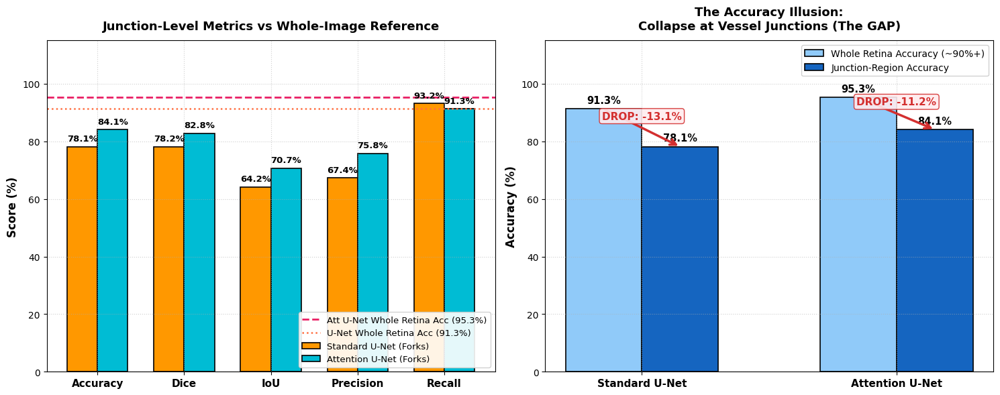

✓ Saved quantitative proof figure to: /content/drive/MyDrive/MINI_PROJECT/outputs/junction_region_metrics.png


In [18]:
# ====================================================================================
# VISUAL REPRESENTATION 2: METRICS COMPARISON & THE GAP COLLAPSE CHARTS
# ====================================================================================
import os
import numpy as np
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# -------------------------------------------------------------
# Panel 1: Grouped Bar Chart (Junction-Region Metrics)
# -------------------------------------------------------------
metric_keys = ['Accuracy', 'Dice', 'IoU', 'Precision', 'Recall']
u_j_vals = [u_jnc_avg[m] * 100 for m in metric_keys]
a_j_vals = [a_jnc_avg[m] * 100 for m in metric_keys]

x = np.arange(len(metric_keys))
w = 0.35

b1 = ax1.bar(x - w/2, u_j_vals, w, label='Standard U-Net (Forks)', color='#ff9800', edgecolor='black', linewidth=1.2)
b2 = ax1.bar(x + w/2, a_j_vals, w, label='Attention U-Net (Forks)', color='#00bcd4', edgecolor='black', linewidth=1.2)

# Reference dashed lines for whole-image scores
ax1.axhline(y=a_pix_avg['Accuracy'] * 100, color='#e91e63', linestyle='--', linewidth=2,
            label=f"Att U-Net Whole Retina Acc ({a_pix_avg['Accuracy']*100:.1f}%)")
ax1.axhline(y=u_pix_avg['Accuracy'] * 100, color='#ff7043', linestyle=':', linewidth=1.8,
            label=f"U-Net Whole Retina Acc ({u_pix_avg['Accuracy']*100:.1f}%)")

ax1.set_ylabel('Score (%)', fontsize=12, fontweight='bold')
ax1.set_title('Junction-Level Metrics vs Whole-Image Reference', fontsize=13, fontweight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(metric_keys, fontsize=11, fontweight='bold')
ax1.set_ylim(0, 115)
ax1.legend(loc='lower right', framealpha=0.9, fontsize=9.5)
ax1.grid(True, linestyle=':', alpha=0.6)

for rects in [b1, b2]:
    for r in rects:
        h = r.get_height()
        ax1.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# -------------------------------------------------------------
# Panel 2: The Accuracy Collapse at Junctions (The GAP)
# -------------------------------------------------------------
models = ['Standard U-Net', 'Attention U-Net']
x2 = np.arange(len(models))
w2 = 0.30

pix_acc = [u_pix_avg['Accuracy'] * 100, a_pix_avg['Accuracy'] * 100]
jnc_acc = [u_jnc_avg['Accuracy'] * 100, a_jnc_avg['Accuracy'] * 100]

b_pix = ax2.bar(x2 - w2/2, pix_acc, w2, label='Whole Retina Accuracy (~90%+)', color='#90caf9', edgecolor='black', linewidth=1.2)
b_jnc = ax2.bar(x2 + w2/2, jnc_acc, w2, label='Junction-Region Accuracy', color='#1565c0', edgecolor='black', linewidth=1.2)

ax2.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax2.set_title('The Accuracy Illusion:\nCollapse at Vessel Junctions (The GAP)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xticks(x2)
ax2.set_xticklabels(models, fontsize=11, fontweight='bold')
ax2.set_ylim(0, 115)
ax2.legend(loc='upper right', framealpha=0.9, fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)

for rects in [b_pix, b_jnc]:
    for r in rects:
        h = r.get_height()
        ax2.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10.5, fontweight='bold')

# Draw Drop Arrows and GAP annotations
u_drop = jnc_acc[0] - pix_acc[0]
a_drop = jnc_acc[1] - pix_acc[1]
for idx, (mx, pa, ja, drop) in enumerate(zip(x2, pix_acc, jnc_acc, [u_drop, a_drop])):
    ax2.annotate("", xy=(mx + w2/2, ja), xytext=(mx - w2/2, pa),
                 arrowprops=dict(arrowstyle="->", color="#d32f2f", lw=2.5, mutation_scale=16))
    mid_y = (pa + ja) / 2
    ax2.text(mx, mid_y + 3, f"DROP: {drop:.1f}%", color="#d32f2f",
             fontsize=11, fontweight='bold', ha='center',
             bbox=dict(boxstyle="round,pad=0.25", facecolor="#ffebee", edgecolor="#d32f2f", alpha=0.9))

plt.tight_layout()
save_path2 = "/content/drive/MyDrive/MINI_PROJECT/outputs/junction_region_metrics.png"
plt.savefig(save_path2, dpi=200, bbox_inches='tight')
plt.show()

print(f"✓ Saved quantitative proof figure to: {save_path2}")